In [2]:

%pip install earthengine-api


^C
Note: you may need to restart the kernel to use updated packages.


In [3]:

import ee

ee.Authenticate()


c:\Users\jazmi\anaconda3\Lib\site-packages\google\api_core\_python_version_support.py:254: FutureWarning: You are using a Python version (3.11.4) which Google will stop supporting in new releases of google.api_core once it reaches its end of life (2027-10-24). Please upgrade to the latest Python version, or at least Python 3.12, to continue receiving updates for google.api_core past that date.
  warnings.warn(message, FutureWarning)
c:\Users\jazmi\anaconda3\Lib\site-packages\google\api_core\_python_package_support.py:206: FutureWarning: Package google.api_core depends on grpcio, currently installed at version 1.67.0. grpcio < 1.83.0 does not support Post-Quantum Cryptography (PQC). Support for non-PQC environments is deprecated. In April 2027, Google Cloud Python packages will raise their minimum requirements (including google-api-core, grpcio, and grpcio-status) to enforce grpcio >= 1.83.0. For more details on Google Cloud's post-quantum security migration, visit: https://cloud.google

True

In [ ]:
%pip install geemap

  Obtaining dependency information for geemap from https://files.pythonhosted.org/packages/96/4f/fb3392a41254afc656c6dd1ea4b9936a012e451fbe5e934fbda81878a6c3/geemap-0.37.2-py3-none-any.whl.metadata
  Obtaining dependency information for anywidget from https://files.pythonhosted.org/packages/8e/c2/8fec8e8e2eb920cc2280f569144080cd58622a2eda83bfa4c0c354a63264/anywidget-0.11.0-py3-none-any.whl.metadata
  Obtaining dependency information for bqplot from https://files.pythonhosted.org/packages/cd/7e/7a5ffa173dd1cffde4f6f41a7dcc8ef4cefdd3bb9cc6cab8341a4802b686/bqplot-0.13.1-py2.py3-none-any.whl.metadata
  Obtaining dependency information for eerepr>=0.1.0 from https://files.pythonhosted.org/packages/15/3a/b766f6f20c5d15fe99f7c52888da2f315ffaec71cb9f06997ec627b0dfbf/eerepr-0.1.3-py3-none-any.whl.metadata
  Obtaining dependency information for folium>=0.17.0 from https://files.pythonhosted.org/packages/b5/a8/5f764f333204db0390362a4356d03a43626997f26818a0e9396f1b3bd8c9/folium-0.20.0-py2.py3-none

In [4]:
import ee

ee.Initialize(project="geospatialfinalproject")

print(ee.String("Earth Engine connected!").getInfo())

Earth Engine connected!


In [5]:

import ee
import geopandas as gpd
import pandas as pd

# Initialize Earth Engine
ee.Initialize(project="geospatialfinalproject")
      
# Load your Western NC study boundary
boundary = gpd.read_file("western_nc_helene.geojson")
boundary = boundary.to_crs("EPSG:4326")

# Convert the boundary to Earth Engine geometry
geometry = boundary.geometry.union_all().__geo_interface__
aoi = ee.Geometry(geometry)

# Display the boundary information
print("Boundary loaded successfully!")
print("Coordinate system:", boundary.crs)
print("Boundary area (degrees squared):",
      round(boundary.geometry.union_all().area, 4))


c:\Users\jazmi\anaconda3\Lib\site-packages\pandas\core\computation\expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.8.4' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
c:\Users\jazmi\anaconda3\Lib\site-packages\pandas\core\arrays\masked.py:56: UserWarning: Pandas requires version '1.4.2' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


Boundary loaded successfully!
Coordinate system: EPSG:4326
Boundary area (degrees squared): 1.8688


In [6]:

s2 = (
    ee.ImageCollection("COPERNICUS/S2_SR_HARMONIZED")
    .filterBounds(aoi)
    .filterDate("2023-01-01", "2024-10-01")
    .filter(ee.Filter.lt("CLOUDY_PIXEL_PERCENTAGE", 80))
)

total_scenes = s2.size().getInfo()

print("Total Sentinel-2 scenes found:", total_scenes)


Total Sentinel-2 scenes found: 1318


In [47]:

s3 = (
    ee.ImageCollection("COPERNICUS/S2_SR_HARMONIZED")
    .filterBounds(aoi)
    .filterDate("2024-10-01", "2026-01-01")
    .filter(ee.Filter.lt("CLOUDY_PIXEL_PERCENTAGE", 80))
)

total_scenes_post = s3.size().getInfo()

print("Total Sentinel-2 scenes found:", total_scenes_post)


Total Sentinel-2 scenes found: 1156


In [11]:
# Create a list of months: Jan 2023 through Sep 2024
months = pd.date_range(
    start="2023-01-01",
    end="2024-09-01",
    freq="MS"
)

monthly_counts = []

for month in months:
    start = ee.Date(month.strftime("%Y-%m-%d"))
    end = start.advance(1, "month")

    # Count scenes available during this month
    count = (
        s2.filterDate(start, end)
        .size()
        .getInfo()
    )

    monthly_counts.append({
        "Month": month.strftime("%Y-%m"),
        "Scene_Count": count
    })

# Display results as a table
availability = pd.DataFrame(monthly_counts)
display(availability)

# Save the table to a CSV file
availability.to_csv(
    "sentinel2_pre_monthly_availability.csv",
    index=False
)


,Month,Scene_Count
0,2023-01,64
1,2023-02,38
2,2023-03,47
3,2023-04,54
4,2023-05,83
5,2023-06,74
6,2023-07,62
7,2023-08,60
8,2023-09,72
9,2023-10,83


In [48]:
# Create a list of months: Septem 2024 through Januaty 2025
months = pd.date_range(
    start="2024-10-01",
    end="2026-01-01",
    freq="MS"
)

monthly_counts = []

for month in months:
    start = ee.Date(month.strftime("%Y-%m-%d"))
    end = start.advance(1, "month")

    # Count scenes available during this month
    count = (
        s2.filterDate(start, end)
        .size()
        .getInfo()
    )

    monthly_counts.append({
        "Month": month.strftime("%Y-%m"),
        "Scene_Count": count
    })

# Display results as a table
availability = pd.DataFrame(monthly_counts)
display(availability)

# Save the table to a CSV file
availability.to_csv(
    "sentinel2_post_monthly_availability.csv",
    index=False
)

,Month,Scene_Count
0,2024-10,72
1,2024-11,20
2,2024-12,21
3,2025-01,37
4,2025-02,35
5,2025-03,54
6,2025-04,30
7,2025-05,11
8,2025-06,28
9,2025-07,38


In [12]:

# Retrieve metadata for all matching scenes
scene_list = s2.sort("system:time_start").toList(s2.size())

scene_data = scene_list.map(
    lambda image: ee.Feature(
        None,
        {
            "Date": ee.Date(
                ee.Image(image).get("system:time_start")
            ).format("YYYY-MM-dd"),
            "Month": ee.Date(
                ee.Image(image).get("system:time_start")
            ).format("YYYY-MM"),
            "CloudCover": ee.Image(image).get(
                "CLOUDY_PIXEL_PERCENTAGE"
            ),
            "ImageID": ee.Image(image).id()
        }
    )
)

# Convert Earth Engine metadata to a Python table
features = ee.FeatureCollection(scene_data).getInfo()["features"]

scenes_df = pd.DataFrame([
    feature["properties"] for feature in features
])

scenes_df = scenes_df.sort_values(
    ["Month", "Date"]
).reset_index(drop=True)

display(scenes_df)

# Save the metadata
scenes_df.to_csv("sentinel2_scene_details.csv", index=False)

print("Total scenes:", len(scenes_df))
print("Months represented:", scenes_df["Month"].nunique())


,CloudCover,Date,ImageID,Month
0,20.394249,2023-01-01,20230101T161701_20230101T161745_T17SMA,2023-01
1,57.440513,2023-01-01,20230101T161701_20230101T161745_T17SMV,2023-01
2,63.987505,2023-01-01,20230101T161701_20230101T161745_T17SLV,2023-01
3,75.667673,2023-01-01,20230101T161701_20230101T161745_T17SKV,2023-01
4,63.466775,2023-01-01,20230101T161701_20230101T161745_T16SGE,2023-01
...,...,...,...,...
1313,5.107637,2024-09-22,20240922T161001_20240922T162015_T16SGE,2024-09
1314,0.506498,2024-09-22,20240922T161001_20240922T162015_T17SMU,2024-09
1315,0.956012,2024-09-22,20240922T161001_20240922T162015_T17SLU,2024-09
1316,2.055107,2024-09-22,20240922T161001_20240922T162015_T17SKU,2024-09


Total scenes: 1318
Months represented: 21


In [49]:

# Retrieve metadata for all matching post-hurricane scenes
scene_list_post = s3.sort("system:time_start").toList(s3.size())

scene_data_post = scene_list_post.map(
    lambda image: ee.Feature(
        None,
        {
            "Date": ee.Date(
                ee.Image(image).get("system:time_start")
            ).format("YYYY-MM-dd"),
            "Month": ee.Date(
                ee.Image(image).get("system:time_start")
            ).format("YYYY-MM"),
            "CloudCover": ee.Image(image).get(
                "CLOUDY_PIXEL_PERCENTAGE"
            ),
            "ImageID": ee.Image(image).id()
        }
    )
)

# Convert Earth Engine metadata to a Python table
features_post = ee.FeatureCollection(
    scene_data_post
).getInfo()["features"]

scenes_df_post = pd.DataFrame([
    feature["properties"] for feature in features_post
])

scenes_df_post = scenes_df_post.sort_values(
    ["Month", "Date"]
).reset_index(drop=True)

display(scenes_df_post)

# Save the post-hurricane metadata
scenes_df_post.to_csv(
    "sentinel2_post_hurricane_scene_details.csv",
    index=False
)

print("Total post-hurricane scenes:", len(scenes_df_post))
print("Months represented:", scenes_df_post["Month"].nunique())



,CloudCover,Date,ImageID,Month
0,34.789583,2024-10-02,20241002T161111_20241002T161350_T17SMA,2024-10
1,42.359120,2024-10-02,20241002T161111_20241002T161350_T17SLA,2024-10
2,12.829025,2024-10-02,20241002T161111_20241002T161350_T17SMV,2024-10
3,19.091499,2024-10-02,20241002T161111_20241002T161350_T17SLV,2024-10
4,12.275577,2024-10-02,20241002T161111_20241002T161350_T17SKV,2024-10
...,...,...,...,...
1151,58.010834,2025-12-31,20251231T162721_20251231T162723_T17SKV,2025-12
1152,45.942608,2025-12-31,20251231T162721_20251231T162723_T16SGE,2025-12
1153,0.000000,2025-12-31,20251231T162721_20251231T162723_T17SLU,2025-12
1154,0.713825,2025-12-31,20251231T162721_20251231T162723_T17SKU,2025-12


Total post-hurricane scenes: 1156
Months represented: 15


In [13]:

# Summarize scene cloud cover
print(scenes_df["CloudCover"].describe())

# Compare how many scenes remain at different thresholds
thresholds = [10, 20, 30, 50, 80]

cloud_summary = pd.DataFrame([
    {
        "MaxCloudCover": threshold,
        "ScenesRemaining": (
            scenes_df["CloudCover"] <= threshold
        ).sum()
    }
    for threshold in thresholds
])

display(cloud_summary)


count    1318.000000
mean       29.106952
std        25.772526
min         0.000000
25%         3.211585
50%        24.074945
75%        50.128427
max        79.986674
Name: CloudCover, dtype: float64


,MaxCloudCover,ScenesRemaining
0,10,449
1,20,605
2,30,739
3,50,986
4,80,1318


In [51]:

# Summarize post-hurricane scene cloud cover
print(scenes_df_post["CloudCover"].describe())

# Compare how many post-hurricane scenes remain at different thresholds
thresholds = [10, 20, 30, 50, 80]

cloud_summary_post = pd.DataFrame([
    {
        "MaxCloudCover": threshold,
        "ScenesRemaining": (
            scenes_df_post["CloudCover"] <= threshold
        ).sum()
    }
    for threshold in thresholds
])

display(cloud_summary_post)


count    1156.000000
mean       27.893762
std        25.198762
min         0.000000
25%         3.346116
50%        21.002601
75%        49.472756
max        79.974824
Name: CloudCover, dtype: float64


,MaxCloudCover,ScenesRemaining
0,10,400
1,20,567
2,30,677
3,50,871
4,80,1156


In [15]:

s2_filtered = s2.filter(
    ee.Filter.lt("CLOUDY_PIXEL_PERCENTAGE", 20)
)

for month in months:
    start = ee.Date(month.strftime("%Y-%m-%d"))
    end = start.advance(1, "month")

    count = s2_filtered.filterDate(start, end).size().getInfo()

    print(month.strftime("%Y-%m"), count)


2023-01 21
2023-02 23
2023-03 39
2023-04 29
2023-05 31
2023-06 21
2023-07 16
2023-08 21
2023-09 23
2023-10 53
2023-11 36
2023-12 28
2024-01 30
2024-02 40
2024-03 38
2024-04 50
2024-05 12
2024-06 17
2024-07 16
2024-08 37
2024-09 24


In [55]:

# Filter post-hurricane scenes to less than 20% cloud cover
s3_filtered = s3.filter(
    ee.Filter.lt("CLOUDY_PIXEL_PERCENTAGE", 20)
)

# Count scenes for each post-hurricane month
for month in post_months:
    start = ee.Date(month.strftime("%Y-%m-%d"))
    end = start.advance(1, "month")

    count = s3_filtered.filterDate(start, end).size().getInfo()

    print(month.strftime("%Y-%m"), count)


2024-10 72
2024-11 20
2024-12 21
2025-01 37
2025-02 35
2025-03 54
2025-04 30
2025-05 11
2025-06 28
2025-07 38
2025-08 27
2025-09 34
2025-10 54
2025-11 63
2025-12 43
2026-01 0


In [58]:

import ee
import pandas as pd

# Initialize Google Earth Engine
ee.Initialize(project="geospatialfinalproject")

# Sentinel-2 bands
bands = ["B2", "B3", "B4", "B8", "B11", "B12"]

# --------------------------------------------------
# 1. Cloud masking function
# --------------------------------------------------

def mask_clouds(image):
    scl = image.select("SCL")

    # Mask defective pixels, cloud shadows, clouds,
    # cirrus, and snow
    clear = (
        scl.neq(1)
        .And(scl.neq(3))
        .And(scl.neq(8))
        .And(scl.neq(9))
        .And(scl.neq(10))
        .And(scl.neq(11))
    )

    return (
        image.select(bands)
        .updateMask(clear)
        .multiply(0.0001)
        .copyProperties(
            image,
            ["system:time_start", "CLOUDY_PIXEL_PERCENTAGE"]
        )
    )


# --------------------------------------------------
# 2. Load the original Sentinel-2 collection
# --------------------------------------------------

s2_all = (
    ee.ImageCollection("COPERNICUS/S2_SR_HARMONIZED")
    .filterBounds(aoi)
    .filter(
        ee.Filter.lt("CLOUDY_PIXEL_PERCENTAGE", 20)
    )
)

# Pre-hurricane scenes: Jan 2023 through Sep 25, 2024
s2 = s2_all.filterDate(
    "2023-01-01", "2024-09-26"
)

# Post-hurricane scenes: Oct 2024 through Sep 2026
s3 = s2_all.filterDate(
    "2024-10-01", "2026-01-01"
)

print("Pre-hurricane scenes:", s2.size().getInfo())
print("Post-hurricane scenes:", s3.size().getInfo())


# --------------------------------------------------
# 3. Apply the cloud mask separately
# --------------------------------------------------

s2_clear = s2.map(mask_clouds)
s3_clear = s3.map(mask_clouds)


# --------------------------------------------------
# 4. Monthly composite function
# --------------------------------------------------

def make_monthly_composite(
    collection, start_date, end_date, label
):
    start = ee.Date(start_date)
    end = ee.Date(end_date)

    monthly_collection = collection.filterDate(
        start, end
    )

    return (
        monthly_collection.median()
        .clip(aoi)
        .set("month", label)
        .set("scene_count", monthly_collection.size())
        .set("system:time_start", start.millis())
    )


# --------------------------------------------------
# 5. Create pre-hurricane monthly composites
#    January 2023 through August 2024
# --------------------------------------------------

pre_months = pd.date_range(
    "2023-01-01", "2024-08-01", freq="MS"
)

pre_composites = [
    make_monthly_composite(
        s2_clear,
        month.strftime("%Y-%m-%d"),
        (
            month + pd.offsets.MonthBegin(1)
        ).strftime("%Y-%m-%d"),
        month.strftime("%Y-%m")
    )
    for month in pre_months
]

print(
    "Pre-hurricane monthly composites:",
    len(pre_composites)
)


# --------------------------------------------------
# 6. Create the separate pre-storm September 2024
#    composite: September 1 through September 25
# --------------------------------------------------

september_pre = make_monthly_composite(
    s2_clear,
    "2024-09-01",
    "2024-09-26",
    "2024-09-pre"
)

print(
    "September pre-storm scenes:",
    september_pre.get("scene_count").getInfo()
)


# --------------------------------------------------
# 7. Create post-hurricane monthly composites
#    October 2024 through September 2026
# --------------------------------------------------

post_months = pd.date_range(
    "2024-10-01", "2026-01-01", freq="MS"
)

post_composites = [
    make_monthly_composite(
        s3_clear,
        month.strftime("%Y-%m-%d"),
        (
            month + pd.offsets.MonthBegin(1)
        ).strftime("%Y-%m-%d"),
        month.strftime("%Y-%m")
    )
    for month in post_months
]

print(
    "Post-hurricane monthly composites:",
    len(post_composites)
)



Pre-hurricane scenes: 605
Post-hurricane scenes: 567
Pre-hurricane monthly composites: 20
September pre-storm scenes: 24
Post-hurricane monthly composites: 16


In [313]:

# Combine all monthly composites
all_composites = (
    pre_composites
    + [september_pre]
    + post_composites
)

# Summarize scene counts for each composite
composite_summary = []

for image in all_composites:
    info = image.toDictionary(
        ["month", "scene_count"]
    ).getInfo()

    composite_summary.append({
        "Month": info.get("month"),
        "SceneCount": info.get("scene_count")
    })

# Create and sort the summary table
composite_df = pd.DataFrame(composite_summary)

composite_df = composite_df.sort_values(
    "Month"
).reset_index(drop=True)

display(composite_df)

# Save the summary
composite_df.to_csv(
    "sentinel2_composite_scene_counts.csv",
    index=False
)

print("Total composites:", len(composite_df))
print("Composites with zero scenes:",
      (composite_df["SceneCount"] == 0).sum())



KeyboardInterrupt: 

In [62]:

def get_valid_pixel_percentage(image):
    valid = image.select("B4").mask().rename("valid")

    stats = valid.reduceRegion(
        reducer=ee.Reducer.mean(),
        geometry=aoi,
        scale=100,
        maxPixels=1e10,
        bestEffort=True
    )

    result = stats.get("valid").getInfo()

    return 0.0 if result is None else result * 100


coverage_results = []

for image in all_composites:
    info = image.toDictionary(
        ["month", "scene_count"]
    ).getInfo()

    band_names = image.bandNames().getInfo()

    if not band_names or info.get("scene_count", 0) == 0:
        coverage_results.append({
            "Month": info.get("month"),
            "SceneCount": info.get("scene_count"),
            "ValidPixelPercent": None,
            "Status": "Empty composite"
        })
        continue

    coverage = get_valid_pixel_percentage(image)

    coverage_results.append({
        "Month": info.get("month"),
        "SceneCount": info.get("scene_count"),
        "ValidPixelPercent": round(coverage, 2),
        "Status": "Available"
    })

coverage_df = pd.DataFrame(coverage_results)

display(coverage_df)

coverage_df.to_csv(
    "sentinel2_composite_coverage.csv",
    index=False
)


,Month,SceneCount,ValidPixelPercent,Status
0,2023-01,21,98.48,Available
1,2023-02,23,33.02,Available
2,2023-03,39,95.02,Available
3,2023-04,29,99.82,Available
4,2023-05,31,86.30,Available
5,2023-06,21,68.39,Available
6,2023-07,16,52.86,Available
7,2023-08,21,57.35,Available
8,2023-09,23,98.01,Available
9,2023-10,53,99.93,Available


In [23]:

import ee
import geemap

Map = geemap.Map()
Map.centerObject(aoi, 8)

target_months = [
    "2023-09",
    "2024-09",
    "2025-09",
    "2026-09"
]

for image in all_composites:
    # Read the image's month property
    info = ee.Image(image).toDictionary(
        ["month", "scene_count"]
    ).getInfo()

    month = str(info.get("month", ""))

    # Display only the four September composites
    if month in target_months:
        Map.addLayer(
            ee.Image(image).clip(aoi),
            {
                "bands": ["B4", "B3", "B2"],
                "min": 0,
                "max": 3000,
                "gamma": 1.2
            },
            month,
            False
        )

        print(
            f"Displaying {month}, "
            f"scenes: {info.get('scene_count', 'unknown')}"
        )

# Add study boundary
boundary = ee.FeatureCollection([
    ee.Feature(aoi)
]).style(
    color="FFFFFF",
    fillColor="00000000",
    width=2
)

Map.addLayer(boundary, {}, "Study boundary", True)

display(Map)



Displaying 2023-09, scenes: 23
Displaying 2025-09, scenes: 34


Map(center=[35.47767648765379, -82.78681753304522], controls=(WidgetControl(options=['position', 'transparent_…

In [35]:

def add_labeled_indices(image):
    # Require positive reflectance in the bands used for the indices
    valid = (
        image.select("B8").gt(0)
        .And(image.select("B4").gt(0))
        .And(image.select("B11").gt(0))
        .And(image.select("B12").gt(0))
    )

    ndvi = (
        image.normalizedDifference(["B8", "B4"])
        .rename("NDVI")
    )

    ndmi = (
        image.normalizedDifference(["B8", "B11"])
        .rename("NDMI")
    )

    nbr = (
        image.normalizedDifference(["B8", "B12"])
        .rename("NBR")
    )

    indices = ee.Image.cat([ndvi, ndmi, nbr]).updateMask(valid)

    return (
        image.addBands(indices, overwrite=True)
        .copyProperties(
            image,
            ["month", "scene_count", "system:time_start"]
        )
    )

pre_index_composites = [
    add_labeled_indices(ee.Image(image))
    for image in pre_composites
]


In [66]:
# Add NDVI, NDMI, and NBR to post-hurricane composites

# Remove images with zero bands
post_composites_filtered = [
    ee.Image(image)
    for image in post_composites
    if ee.Image(image).bandNames().size().getInfo() > 0
]

print(
    "Post-hurricane composites after removing empty images:",
    len(post_composites_filtered)
)

# Add labeled indices to the remaining images
post_index_composites = [
    add_labeled_indices(image)
    for image in post_composites_filtered
]

print(
    "Post-hurricane index composites:",
    len(post_index_composites)
)


Post-hurricane composites after removing empty images: 15
Post-hurricane index composites: 15


In [86]:
# Create the September 2025 composite
september_2025_collection = s3_clear.filterDate(
    "2025-09-01",
    "2025-10-01"
)

september_2025_image = ee.Image(
    september_2025_collection.median()
).clip(aoi)

# Calculate NDVI, NDMI, and NBR
september_2025_index = ee.Image(
    add_labeled_indices(september_2025_image)
)

# Check the bands
print(september_2025_index.bandNames().getInfo())

['B2', 'B3', 'B4', 'B8', 'B11', 'B12', 'NDVI', 'NDMI', 'NBR']


In [67]:
# Inspect the first post-hurricane composite
image = ee.Image(post_index_composites[0])

print("Month:", image.get("month").getInfo())
print("Bands:", image.bandNames().getInfo())

Month: 2024-10
Bands: ['B2', 'B3', 'B4', 'B8', 'B11', 'B12', 'NDVI', 'NDMI', 'NBR']


In [70]:
for image in post_index_composites:
    image = ee.Image(image)
    month = image.get("month").getInfo()

    if month == "2024-10":
        print("Month:", month)

        stats = image.select(
            ["NDVI", "NDMI", "NBR"]
        ).reduceRegion(
            reducer=ee.Reducer.minMax().combine(
                reducer2=ee.Reducer.mean(),
                sharedInputs=True
            ),
            geometry=aoi,
            scale=20,
            maxPixels=1e9,
            bestEffort=True
        ).getInfo()

        print(stats)

Month: 2024-10
{'NBR_max': 0.9983766233766234, 'NBR_mean': 0.5085261389440382, 'NBR_min': -0.994764397905759, 'NDMI_max': 0.9983484723369116, 'NDMI_mean': 0.2043905816969771, 'NDMI_min': -0.9961977186311786, 'NDVI_max': 0.9996886674968867, 'NDVI_mean': 0.7691715594607831, 'NDVI_min': -0.9965811965811965}


In [71]:
for image in post_index_composites:
    image = ee.Image(image)
    month = image.get("month").getInfo()

    if month == "2024-10":
        stats = image.select(
            ["NDVI", "NDMI", "NBR"]
        ).reduceRegion(
            reducer=ee.Reducer.percentile([5, 50, 95]),
            geometry=aoi,
            scale=20,
            maxPixels=1e9,
            bestEffort=True
        ).getInfo()

        print("Month:", month)
        print(stats)

Month: 2024-10
{'NBR_p5': 0.19143874930469912, 'NBR_p50': 0.5508059334454428, 'NBR_p95': 0.6912830061145243, 'NDMI_p5': -0.05855569434325772, 'NDMI_p50': 0.23048659772647298, 'NDMI_p95': 0.38661504038832756, 'NDVI_p5': 0.511746936651983, 'NDVI_p50': 0.8164576194776746, 'NDVI_p95': 0.8865287924391985}


In [77]:
for image in pre_index_composites:
    image = ee.Image(image)

    info = image.toDictionary(
        ["month", "scene_count"]
    ).getInfo()

    bands = image.bandNames().getInfo()

    print(
        "Month:", info.get("month"),
        "| Scenes:", info.get("scene_count"),
        "| Bands:", bands
    )

Month: 2023-01 | Scenes: 21 | Bands: ['B2', 'B3', 'B4', 'B8', 'B11', 'B12', 'NDVI', 'NDMI', 'NBR']
Month: 2023-02 | Scenes: 23 | Bands: ['B2', 'B3', 'B4', 'B8', 'B11', 'B12', 'NDVI', 'NDMI', 'NBR']
Month: 2023-03 | Scenes: 39 | Bands: ['B2', 'B3', 'B4', 'B8', 'B11', 'B12', 'NDVI', 'NDMI', 'NBR']
Month: 2023-04 | Scenes: 29 | Bands: ['B2', 'B3', 'B4', 'B8', 'B11', 'B12', 'NDVI', 'NDMI', 'NBR']
Month: 2023-05 | Scenes: 31 | Bands: ['B2', 'B3', 'B4', 'B8', 'B11', 'B12', 'NDVI', 'NDMI', 'NBR']
Month: 2023-06 | Scenes: 21 | Bands: ['B2', 'B3', 'B4', 'B8', 'B11', 'B12', 'NDVI', 'NDMI', 'NBR']
Month: 2023-07 | Scenes: 16 | Bands: ['B2', 'B3', 'B4', 'B8', 'B11', 'B12', 'NDVI', 'NDMI', 'NBR']
Month: 2023-08 | Scenes: 21 | Bands: ['B2', 'B3', 'B4', 'B8', 'B11', 'B12', 'NDVI', 'NDMI', 'NBR']
Month: 2023-09 | Scenes: 23 | Bands: ['B2', 'B3', 'B4', 'B8', 'B11', 'B12', 'NDVI', 'NDMI', 'NBR']
Month: 2023-10 | Scenes: 53 | Bands: ['B2', 'B3', 'B4', 'B8', 'B11', 'B12', 'NDVI', 'NDMI', 'NBR']
Month: 202

In [69]:
for image in post_index_composites:
    image = ee.Image(image)

    info = image.toDictionary(
        ["month", "scene_count"]
    ).getInfo()

    bands = image.bandNames().getInfo()

    print(
        "Month:", info.get("month"),
        "| Scenes:", info.get("scene_count"),
        "| Bands:", bands
    )

Month: 2024-10 | Scenes: 72 | Bands: ['B2', 'B3', 'B4', 'B8', 'B11', 'B12', 'NDVI', 'NDMI', 'NBR']
Month: 2024-11 | Scenes: 20 | Bands: ['B2', 'B3', 'B4', 'B8', 'B11', 'B12', 'NDVI', 'NDMI', 'NBR']
Month: 2024-12 | Scenes: 21 | Bands: ['B2', 'B3', 'B4', 'B8', 'B11', 'B12', 'NDVI', 'NDMI', 'NBR']
Month: 2025-01 | Scenes: 37 | Bands: ['B2', 'B3', 'B4', 'B8', 'B11', 'B12', 'NDVI', 'NDMI', 'NBR']
Month: 2025-02 | Scenes: 35 | Bands: ['B2', 'B3', 'B4', 'B8', 'B11', 'B12', 'NDVI', 'NDMI', 'NBR']
Month: 2025-03 | Scenes: 54 | Bands: ['B2', 'B3', 'B4', 'B8', 'B11', 'B12', 'NDVI', 'NDMI', 'NBR']
Month: 2025-04 | Scenes: 30 | Bands: ['B2', 'B3', 'B4', 'B8', 'B11', 'B12', 'NDVI', 'NDMI', 'NBR']
Month: 2025-05 | Scenes: 11 | Bands: ['B2', 'B3', 'B4', 'B8', 'B11', 'B12', 'NDVI', 'NDMI', 'NBR']
Month: 2025-06 | Scenes: 28 | Bands: ['B2', 'B3', 'B4', 'B8', 'B11', 'B12', 'NDVI', 'NDMI', 'NBR']
Month: 2025-07 | Scenes: 38 | Bands: ['B2', 'B3', 'B4', 'B8', 'B11', 'B12', 'NDVI', 'NDMI', 'NBR']
Month: 202

In [79]:
# Find the October 2024 composite
october_image = next(
    ee.Image(image)
    for image in post_index_composites
    if ee.Image(image).get("month").getInfo() == "2024-10"
)

# Display a true-color RGB composite
Map.addLayer(
    october_image.clip(aoi),
    {
        "bands": ["B4", "B3", "B2"],
        "min": 0,
        "max": 0.3,
        "gamma": 1.2
    },
    "October 2024 Sentinel-2 RGB",
    True
)
Map.addLayer(
    october_image.select("NDVI").clip(aoi),
    {
        "min": -0.2,
        "max": 0.9,
        "palette": ["brown", "yellow", "green"]
    },
    "October 2024 NDVI",
    False
)

Map.addLayer(
    october_image.select("NDMI").clip(aoi),
    {
        "min": -0.5,
        "max": 0.5,
        "palette": ["brown", "white", "blue"]
    },
    "October 2024 NDMI",
    False
)

Map.addLayer(
    october_image.select("NBR").clip(aoi),
    {
        "min": -0.5,
        "max": 0.8,
        "palette": ["brown", "white", "green"]
    },
    "October 2024 NBR",
    False
)


Map

Map(bottom=26134.0, center=[35.55904339525896, -82.75451660156251], controls=(WidgetControl(options=['position…

In [82]:
print("Pre-hurricane composites:")
for image in pre_index_composites:
    image = ee.Image(image)
    print(image.get("month").getInfo())

print("\nPost-hurricane composites:")
for image in post_index_composites:
    image = ee.Image(image)
    print(image.get("month").getInfo())

Pre-hurricane composites:
2023-01
2023-02
2023-03
2023-04
2023-05
2023-06
2023-07
2023-08
2023-09
2023-10
2023-11
2023-12
2024-01
2024-02
2024-03
2024-04
2024-05
2024-06
2024-07
2024-08

Post-hurricane composites:
2024-10
2024-11
2024-12
2025-01
2025-02
2025-03
2025-04
2025-05
2025-06
2025-07
2025-08
2025-09
2025-10
2025-11
2025-12


In [87]:
nbr_change_2025 = (
    september_2025_index.select("NBR")
    .subtract(ee.Image(september_pre_index).select("NBR"))
    .rename("NBR_change")
    .clip(aoi)
)

Map.addLayer(
    nbr_change_2025,
    {
        "min": -0.5,
        "max": 0.5,
        "palette": ["red", "white", "green"]
    },
    "NBR Change: September 2025 minus September 2024",
    True
)

Map

Map(bottom=26171.0, center=[35.39352808136067, -81.88110351562501], controls=(WidgetControl(options=['position…

In [89]:
# Identify pixels with a decrease in NBR of 0.1 or more
potential_disturbance = nbr_change_2025.lte(-0.1)

# Display potential disturbance areas
Map.addLayer(
    potential_disturbance.selfMask(),
    {"palette": ["red"]},
    "Potential disturbance: NBR decrease >= 0.1",
    True
)

Map

Map(bottom=26171.0, center=[35.39352808136067, -81.88110351562501], controls=(WidgetControl(options=['position…

In [83]:
# Convert the September composite to an image
september_image = ee.Image(september_pre)

# Calculate NDVI, NDMI, and NBR for September
september_pre_index = add_labeled_indices(september_image)

In [90]:
# Load ESA WorldCover 2021
worldcover = (
    ee.ImageCollection("ESA/WorldCover/v200")
    .first()
    .select("Map")
    .clip(aoi)
)

# Keep tree-cover pixels
forest_mask = worldcover.eq(10).rename("forest")

# Display the forest mask
Map.addLayer(
    forest_mask.selfMask(),
    {"palette": ["006400"]},
    "Forest mask",
    False
)

Map

Map(bottom=26194.0, center=[35.290468565908775, -81.93603515625001], controls=(WidgetControl(options=['positio…

In [91]:
# Mask NBR change to forest pixels
forest_nbr_change = nbr_change_2025.updateMask(forest_mask)

# Highlight larger NBR decreases in forests
forest_disturbance = forest_nbr_change.lte(-0.1)

Map.addLayer(
    forest_disturbance.selfMask(),
    {"palette": ["red"]},
    "Potential forest disturbance",
    True
)

Map

Map(bottom=26194.0, center=[35.290468565908775, -81.93603515625001], controls=(WidgetControl(options=['positio…

In [92]:
# Calculate the area of forest pixels flagged for potential disturbance
disturbed_area = (
    ee.Image.pixelArea()
    .updateMask(forest_disturbance)
    .rename("area_m2")
)

area_stats = disturbed_area.reduceRegion(
    reducer=ee.Reducer.sum(),
    geometry=aoi,
    scale=100,
    maxPixels=1e9,
    tileScale=4
)

area_m2 = area_stats.get("area_m2").getInfo()

if area_m2 is not None:
    print("Potentially disturbed forest area (km²):", area_m2 / 1_000_000)
    print("Potentially disturbed forest area (hectares):", area_m2 / 10_000)
else:
    print("No valid forest pixels met the disturbance threshold.")

Potentially disturbed forest area (km²): 590.1730379003466
Potentially disturbed forest area (hectares): 59017.30379003465


In [93]:
# Total forest area
total_forest_area = (
    ee.Image.pixelArea()
    .updateMask(forest_mask)
    .rename("area_m2")
)

total_forest_stats = total_forest_area.reduceRegion(
    reducer=ee.Reducer.sum(),
    geometry=aoi,
    scale=100,
    maxPixels=1e9,
    tileScale=4
)

total_forest_m2 = total_forest_stats.get("area_m2").getInfo()

# Calculate percentage
if total_forest_m2 is not None and total_forest_m2 > 0:
    total_forest_km2 = total_forest_m2 / 1_000_000
    disturbed_percentage = (area_m2 / total_forest_m2) * 100

    print("Total forest area (km²):", total_forest_km2)
    print("Potentially disturbed forest area (km²):", area_m2 / 1_000_000)
    print("Percentage of forest flagged (%):", disturbed_percentage)
else:
    print("Could not calculate total forest area.")

Total forest area (km²): 16844.099257986807
Potentially disturbed forest area (km²): 590.1730379003466
Percentage of forest flagged (%): 3.5037375929764227


Obtaining Training Labels: 

In [96]:
import ee
import geemap
import geopandas as gpd

# Load Western NC boundary
gdf = gpd.read_file("western_nc_helene.geojson")

# Convert to WGS84
gdf = gdf.to_crs("EPSG:4326")

# Convert to Earth Engine geometry
aoi = geemap.geopandas_to_ee(gdf).geometry()

print("Study boundary loaded")

Study boundary loaded


In [97]:
import requests
import geopandas as gpd
import pandas as pd
from shapely.geometry import shape

service_url = (
    "https://services.nconemap.gov/secure/rest/services/"
    "Imagery/Orthoimagery_Helene_2025/ImageServer"
)

# Request footprint geometries from the image service
params = {
    "where": "1=1",
    "outFields": "objectid",
    "returnGeometry": "true",
    "outSR": 4326,
    "returnIdsOnly": "true",
    "f": "json"
}

response = requests.get(
    service_url + "/query",
    params=params,
    timeout=60
)
response.raise_for_status()

data = response.json()

if "error" in data:
    raise RuntimeError(data["error"])

object_ids = data.get("objectIds", [])

print("Number of imagery records:", len(object_ids))

Number of imagery records: 6778


In [99]:
import requests

service_url = (
    "https://services.nconemap.gov/secure/rest/services/"
    "Imagery/Orthoimagery_Helene_2025/ImageServer"
)

response = requests.get(
    service_url,
    params={"f": "json"},
    timeout=60
)

print("Status code:", response.status_code)
print("URL:", response.url)
print("Response:", response.text[:1000])

Status code: 200
URL: https://services.nconemap.gov/secure/rest/services/Imagery/Orthoimagery_Helene_2025/ImageServer?f=json
Response: {"currentVersion":10.91,"serviceDescription":"<div style='text-align:Left;'><div><div><p><span>Product: These data were acquired by the NC Collaboratory at UNC Chapel Hill utilizing funds appropriated by the NC General Assembly. This orthoimagery data set includes 6 in digital orthoimages in GeoTIFF tiles and 32-bit 4-band (RGBIR).Geographic Extent: 13 counties in NorthCarolina, covering approximately 5,323 total square miles. Counties covered in their entirety for this project included: Alexander, Ashe, Watauga, Avery, Mitchell, Burke, Yancey, McDowell, Rutherford, Buncombe, Henderson, Haywood, and Jackson. Dataset Description: The Helene-North Carolina Priority 1 Lidar and Imagery project called for the planning, acquisition, and processing of imagery data to be collected at a ground sample distance (GSD) of 6 in. Project specifications are based on t

In [100]:
response = requests.get(
    service_url + "/query",
    params={
        "where": "1=1",
        "returnCountOnly": "true",
        "f": "json"
    },
    timeout=60
)

print("Status code:", response.status_code)
print("Response:", response.text[:1000])

Status code: 200
Response: {"count":6778}


In [101]:
params = {
    "where": "1=1",
    "returnIdsOnly": "true",
    "f": "json"
}

response = requests.get(
    service_url + "/query",
    params=params,
    timeout=60
)

print("Status:", response.status_code)
print(response.text[:500])

response.raise_for_status()

data = response.json()
object_ids = data.get("objectIds", [])

print("Number of imagery records:", len(object_ids))

Status: 200
{"objectIdFieldName":"objectid","objectIds":[6779,6780,6781,6782,6783,6784,6785,6786,6787,6788,6789,6790,6791,6792,6793,6794,6795,6796,6797,6798,6799,6800,6801,6802,6803,6804,6805,6806,6807,6808,6809,6810,6811,6812,6813,6814,6815,6816,6817,6818,6819,6820,6821,6822,6823,6824,6825,6826,6827,6828,6829,6830,6831,6832,6833,6834,6835,6836,6837,6838,6839,6840,6841,6842,6843,6844,6845,6846,6847,6848,6849,6850,6851,6852,6853,6854,6855,6856,6857,6858,6859,6860,6861,6862,6863,6864,6865,6866,6867,6868,6869,
Number of imagery records: 6778


In [102]:
params = {
    "objectIds": ",".join(map(str, object_ids[:5])),
    "outFields": "*",
    "returnGeometry": "true",
    "outSR": "4326",
    "f": "json"
}

response = requests.get(
    service_url + "/query",
    params=params,
    timeout=60
)

print("Status:", response.status_code)
print(response.text[:1000])

response.raise_for_status()

data = response.json()

print("Features returned:", len(data.get("features", [])))

Status: 200
{"objectIdFieldName":"objectid","fields":[{"name":"objectid","type":"esriFieldTypeOID","alias":"OBJECTID","domain":null},{"name":"name","type":"esriFieldTypeString","alias":"Name","domain":null,"length":200},{"name":"minps","type":"esriFieldTypeDouble","alias":"MinPS","domain":null},{"name":"maxps","type":"esriFieldTypeDouble","alias":"MaxPS","domain":null},{"name":"lowps","type":"esriFieldTypeDouble","alias":"LowPS","domain":null},{"name":"highps","type":"esriFieldTypeDouble","alias":"HighPS","domain":null},{"name":"category","type":"esriFieldTypeInteger","alias":"Category","domain":{"type":"codedValue","name":"MosaicCatalogItemCategoryDomain","description":"Catalog item categories.","codedValues":[{"name":"Unknown","code":0},{"name":"Primary","code":1},{"name":"Overview","code":2},{"name":"Unprocessed Overview","code":3},{"name":"Partial Overview","code":4},{"name":"Inactive","code":5},{"name":"Uploaded","code":253},{"name":"Incomplete","code":254},{"name":"Custom","code"

In [103]:
%pip install arcgis2geojson


  Obtaining dependency information for arcgis2geojson from https://files.pythonhosted.org/packages/0a/a6/759a1145c07a5a644ea05dacde14f2b02dbdf544e3bda22c4d289829db0d/arcgis2geojson-3.1.3-py3-none-any.whl.metadata


In [105]:
import requests
import geopandas as gpd
from shapely.geometry import shape
from arcgis2geojson import arcgis2geojson

geometries = []

for i in range(0, len(object_ids), 100):
    batch = object_ids[i:i+100]

    params = {
        "objectIds": ",".join(map(str, batch)),
        "outFields": "objectid",
        "returnGeometry": "true",
        "outSR": 4326,
        "f": "json"
    }

    response = requests.get(
        service_url + "/query",
        params=params,
        timeout=60
    )
    response.raise_for_status()

    data = response.json()

    if "error" in data:
        raise RuntimeError(data["error"])

    converted = arcgis2geojson(data)

    for feature in converted.get("features", []):
        geometry = feature.get("geometry")

        if geometry:
            geometries.append(shape(geometry))

footprints = gpd.GeoDataFrame(
    geometry=geometries,
    crs="EPSG:4326"
)

print("Total footprints retrieved:", len(footprints))

Total footprints retrieved: 6778


In [106]:
study = gdf.to_crs("EPSG:32617")
coverage = footprints.to_crs("EPSG:32617")

study_geom = study.geometry.union_all()
coverage_geom = coverage.geometry.union_all()

overlap_geom = study_geom.intersection(coverage_geom)

study_area_km2 = study_geom.area / 1e6
overlap_area_km2 = overlap_geom.area / 1e6

coverage_percent = overlap_area_km2 / study_area_km2 * 100

print(f"Study area: {study_area_km2:.2f} km²")
print(f"Aerial imagery coverage: {overlap_area_km2:.2f} km²")
print(f"Coverage percentage: {coverage_percent:.2f}%")

Study area: 18816.78 km²
Aerial imagery coverage: 11327.06 km²
Coverage percentage: 60.20%


In [110]:
import geemap
import geopandas as gpd

overlap_gdf = gpd.GeoDataFrame(
    geometry=[overlap_geom],
    crs="EPSG:32617"
).to_crs("EPSG:4326")

coverage_ee = geemap.geopandas_to_ee(overlap_gdf)

Map = geemap.Map()
Map.centerObject(aoi, 8)

# Forest pixels
Map.addLayer(
    forest_mask.selfMask(),
    {"palette": ["green"]},
    "Forest Areas"
)

# Aerial imagery footprint
Map.addLayer(
    coverage_ee.style(
        color="blue",
        fillColor="00000000",
        width=2
    ),
    {},
    "Aerial Imagery Coverage"
)

# Study boundary
Map.addLayer(
    aoi,
    {"color": "red"},
    "Western NC Boundary"
)


Map

Map(center=[35.47767648765388, -82.78681753304507], controls=(WidgetControl(options=['position', 'transparent_…

In [111]:
import geemap
from ipyleaflet import TileLayer

Map = geemap.Map()
Map.centerObject(aoi, 9)

# ArcGIS ImageServer tile endpoint
aerial_url = service_url + "/tile/{z}/{y}/{x}"

aerial_layer = TileLayer(
    url=aerial_url,
    name="NC Helene 2025 Aerial Imagery",
    attribution="NC OneMap"
)

Map.add(aerial_layer)

# Aerial imagery coverage outline
Map.addLayer(
    coverage_ee.style(
        color="blue",
        fillColor="00000000",
        width=2
    ),
    {},
    "Aerial Coverage"
)

# Study boundary outline
Map.addLayer(
    ee.FeatureCollection([ee.Feature(aoi)]).style(
        color="red",
        fillColor="00000000",
        width=2
    ),
    {},
    "Study Area"
)

Map

Map(center=[35.47767648765388, -82.78681753304507], controls=(WidgetControl(options=['position', 'transparent_…

Status: 200
Content type: image/jpeg


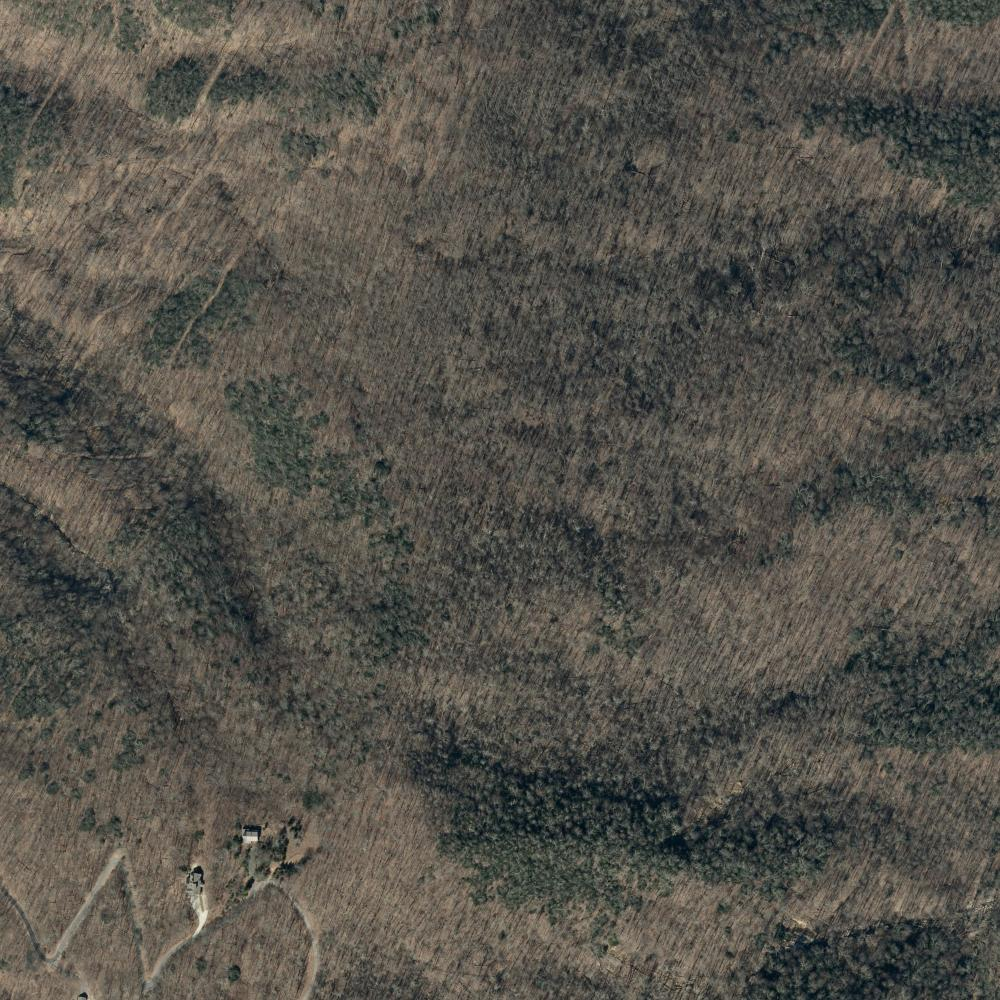

In [113]:
import requests
from IPython.display import display, Image

# Choose a point inside the aerial imagery coverage
point = overlap_geom.representative_point()

# overlap_geom is in EPSG:32617 (meters)
x, y = point.x, point.y

# Request a 1 km x 1 km image
bbox = [x - 500, y - 500, x + 500, y + 500]

params = {
    "bbox": ",".join(map(str, bbox)),
    "bboxSR": 32617,
    "imageSR": 32617,
    "size": "1000,1000",
    "format": "jpg",
    "f": "image"
}

response = requests.get(
    service_url + "/exportImage",
    params=params,
    timeout=120
)

print("Status:", response.status_code)
print("Content type:", response.headers.get("Content-Type"))

response.raise_for_status()

if "image" in response.headers.get("Content-Type", ""):
    display(Image(data=response.content))
else:
    print(response.text[:1000])

In [114]:
import requests

url = "https://services.nconemap.gov/secure/rest/services"

response = requests.get(
    url,
    params={"f": "json"},
    timeout=60
)

response.raise_for_status()
data = response.json()

# Look for imagery-related folders
for folder in data.get("folders", []):
    if "imag" in folder.lower() or "ortho" in folder.lower():
        print(folder)

# Look for imagery-related services
for service in data.get("services", []):
    if "imag" in service["name"].lower() or "ortho" in service["name"].lower():
        print(service["name"], service["type"])

Imagery
ImageryProject
NC1Map_Ortho_Acquisition_Related FeatureServer
NC1Map_Ortho_Acquisition_Related MapServer


In [115]:
import requests

imagery_url = (
    "https://services.nconemap.gov/secure/rest/services/Imagery"
)

response = requests.get(
    imagery_url,
    params={"f": "json"},
    timeout=60
)

response.raise_for_status()
data = response.json()

for service in data.get("services", []):
    print(service["name"], "-", service["type"])

Imagery/DOQQ_NC_1993 - ImageServer
Imagery/DOQQ_NC_CIR_1998 - ImageServer
Imagery/Orthoimagery_1995 - ImageServer
Imagery/Orthoimagery_1996 - ImageServer
Imagery/Orthoimagery_1997 - ImageServer
Imagery/Orthoimagery_1998 - ImageServer
Imagery/Orthoimagery_1999 - ImageServer
Imagery/Orthoimagery_2000 - ImageServer
Imagery/Orthoimagery_2001 - ImageServer
Imagery/Orthoimagery_2002 - ImageServer
Imagery/Orthoimagery_2003 - ImageServer
Imagery/Orthoimagery_2004 - ImageServer
Imagery/Orthoimagery_2005 - ImageServer
Imagery/Orthoimagery_2006 - ImageServer
Imagery/Orthoimagery_2007 - ImageServer
Imagery/Orthoimagery_2008 - ImageServer
Imagery/Orthoimagery_2009 - ImageServer
Imagery/Orthoimagery_2010 - ImageServer
Imagery/Orthoimagery_2012_2015 - ImageServer
Imagery/Orthoimagery_2016_2019 - ImageServer
Imagery/Orthoimagery_20202023_CIR - ImageServer
Imagery/Orthoimagery_20202023_NDVI - ImageServer
Imagery/Orthoimagery_2020_2023_4band_analysis - ImageServer
Imagery/Orthoimagery_2020_2023 - ImageS

Status: 200
Content type: image/jpeg


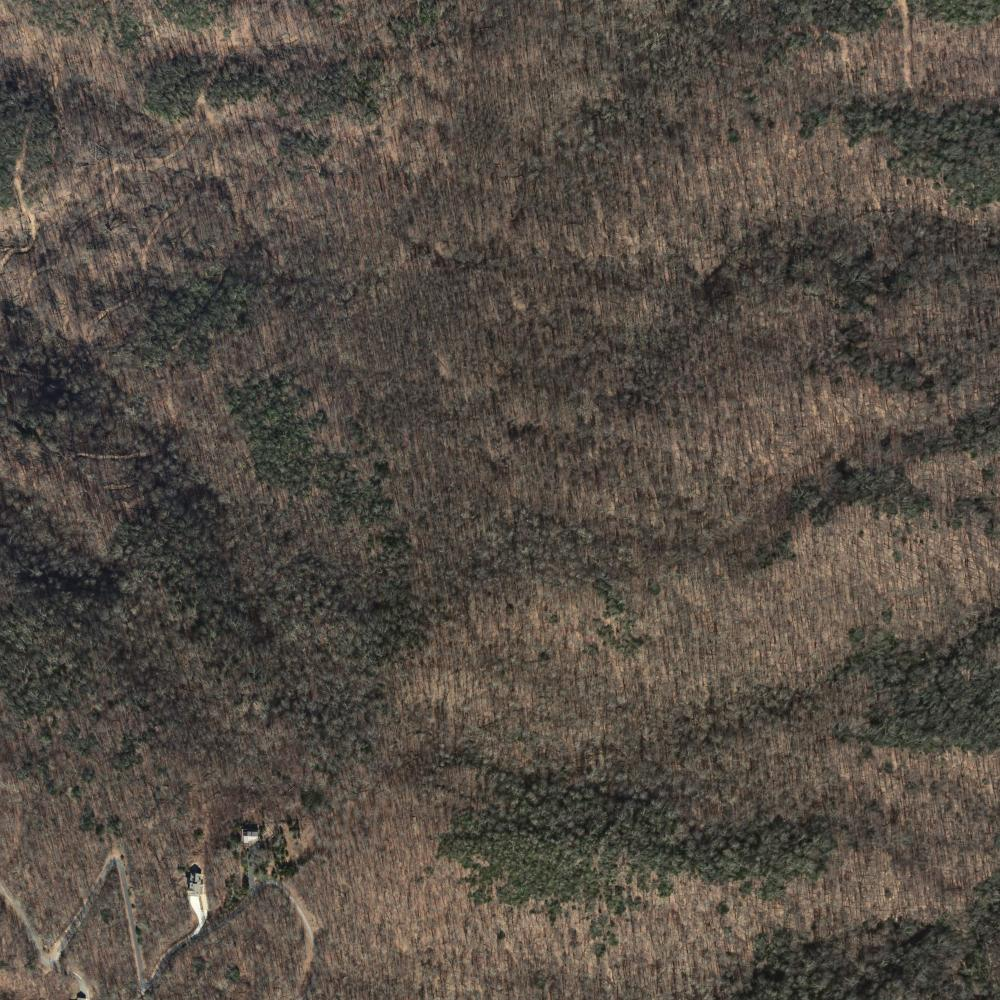

In [116]:
pre_url = (
    "https://services.nconemap.gov/secure/rest/services/"
    "Imagery/Orthoimagery_2020_2023/ImageServer"
)

params = {
    "bbox": ",".join(map(str, bbox)),
    "bboxSR": 32617,
    "imageSR": 32617,
    "size": "1000,1000",
    "format": "jpg",
    "f": "image"
}

response = requests.get(
    pre_url + "/exportImage",
    params=params,
    timeout=120
)

print("Status:", response.status_code)
print("Content type:", response.headers.get("Content-Type"))

response.raise_for_status()

if "image" in response.headers.get("Content-Type", ""):
    display(Image(data=response.content))
else:
    print(response.text[:1000])

In [119]:
params = {
    "geometry": f"{x},{y}",
    "geometryType": "esriGeometryPoint",
    "inSR": 32617,
    "spatialRel": "esriSpatialRelIntersects",
    "outFields": "*",
    "returnGeometry": "false",
    "f": "json"
}

response = requests.get(
    pre_url + "/query",
    params=params,
    timeout=60
)

print("HTTP status:", response.status_code)

data = response.json()
print(data)

HTTP status: 200
{'error': {'code': 500, 'message': 'Error performing query operation', 'details': []}}


In [122]:
import requests
from datetime import datetime, timezone

# Get historical imagery record IDs
r = requests.get(
    pre_url + "/query",
    params={
        "where": "1=1",
        "returnIdsOnly": "true",
        "f": "json"
    },
    timeout=60
)

r.raise_for_status()
ids_data = r.json()

if "error" in ids_data:
    raise RuntimeError(ids_data["error"])

pre_object_ids = ids_data.get("objectIds", [])

print("Total historical records:", len(pre_object_ids))

# Retrieve five records by ID
r = requests.get(
    pre_url + "/query",
    params={
        "objectIds": ",".join(map(str, pre_object_ids[:5])),
        "outFields": "objectid,name,date,category",
        "returnGeometry": "true",
        "outSR": 4326,
        "f": "json"
    },
    timeout=60
)

r.raise_for_status()
pre_data = r.json()

if "error" in pre_data:
    raise RuntimeError(pre_data["error"])

print("Features returned:", len(pre_data.get("features", [])))

for feature in pre_data.get("features", []):
    attrs = feature["attributes"]
    date_value = attrs.get("date")

    if isinstance(date_value, (int, float)):
        date_str = datetime.fromtimestamp(
            date_value / 1000,
            tz=timezone.utc
        ).strftime("%Y-%m-%d")
    else:
        date_str = str(date_value)

    print(attrs.get("name"), "|", date_str)

Total historical records: 59660
Features returned: 5
L01-20202023-3-band-jpeg | None
L02-20202023-3-band-jpeg | None
L03-20202023-3-band-jpeg | None
L04-20202023-3-band-jpeg | None
L05-20202023-3-band-jpeg | None


Status: 200
Content type: image/jpeg


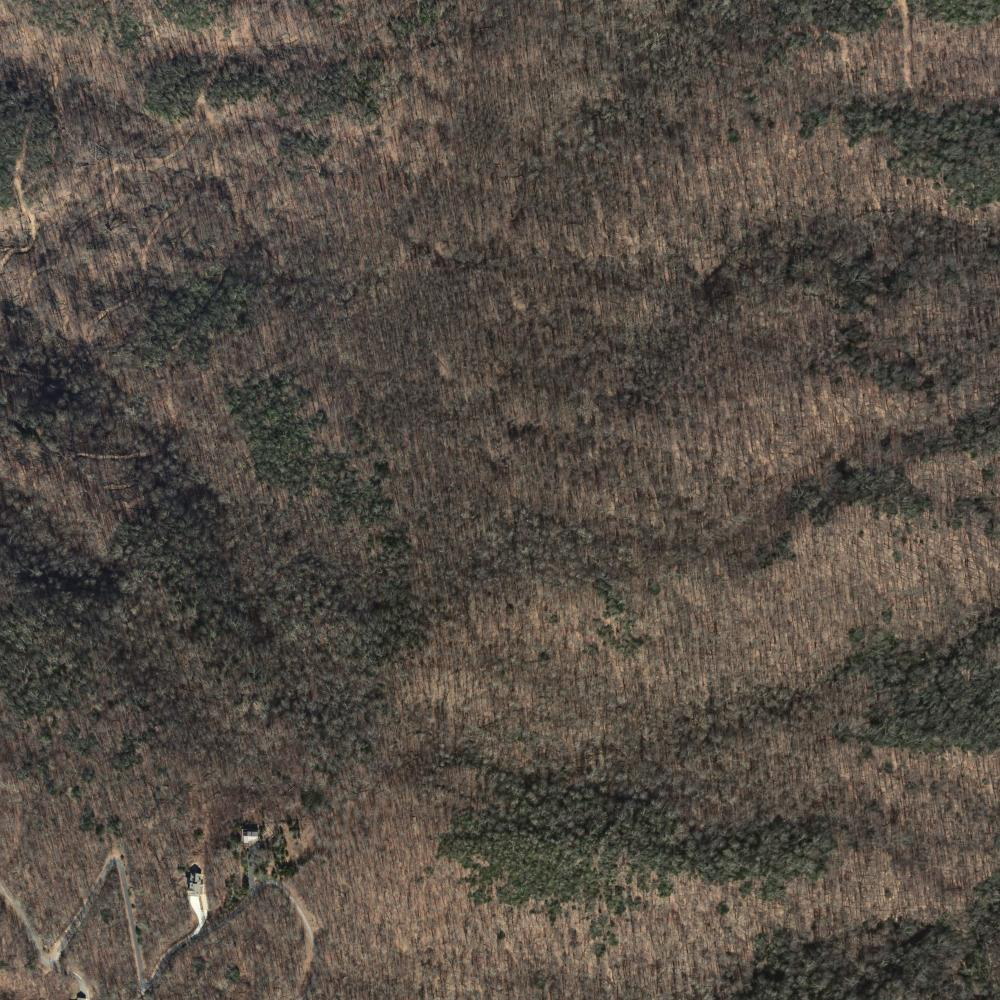

In [125]:
from IPython.display import display, Image

params = {
    "bbox": ",".join(map(str, bbox)),
    "bboxSR": 32617,
    "imageSR": 32617,
    "size": "1000,1000",
    "format": "jpg",
    "f": "image"
}

response = requests.get(
    pre_url + "/exportImage",
    params=params,
    timeout=120
)

print("Status:", response.status_code)
print("Content type:", response.headers.get("Content-Type"))

if response.ok and "image/" in response.headers.get("Content-Type", ""):
    display(Image(data=response.content))
else:
    print(response.text[:500])

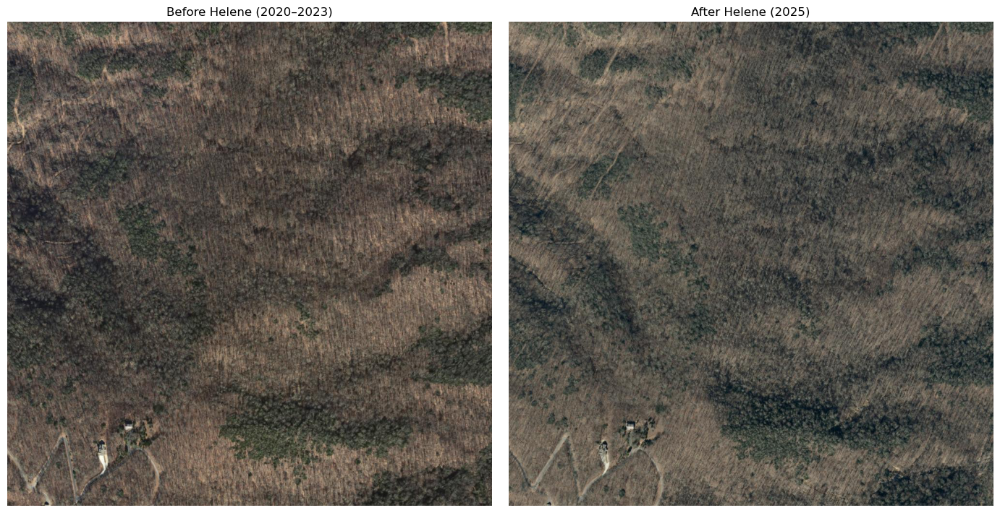

In [126]:
import requests
from PIL import Image
from io import BytesIO
import matplotlib.pyplot as plt

def get_aerial_image(url, bbox):
    params = {
        "bbox": ",".join(map(str, bbox)),
        "bboxSR": 32617,
        "imageSR": 32617,
        "size": "1000,1000",
        "format": "jpg",
        "f": "image"
    }

    response = requests.get(
        url + "/exportImage",
        params=params,
        timeout=120
    )

    response.raise_for_status()

    if "image/" not in response.headers.get("Content-Type", ""):
        raise RuntimeError(response.text[:500])

    return Image.open(BytesIO(response.content)).convert("RGB")


pre_image = get_aerial_image(pre_url, bbox)
post_image = get_aerial_image(service_url, bbox)

fig, axes = plt.subplots(1, 2, figsize=(14, 7))

axes[0].imshow(pre_image)
axes[0].set_title("Before Helene (2020–2023)")
axes[0].axis("off")

axes[1].imshow(post_image)
axes[1].set_title("After Helene (2025)")
axes[1].axis("off")

plt.tight_layout()
plt.show()

In [129]:
# 1 = potentially disturbed forest
damage_candidates = forest_disturbance.selfMask().rename("damage")

# Restrict to aerial imagery coverage
damage_candidates = damage_candidates.clip(
    coverage_ee.geometry()
)
candidate_points = damage_candidates.sample(
    region=coverage_ee.geometry(),
    scale=100,
    numPixels=10000,
    seed=42,
    geometries=True,
    tileScale=4
)

print("Candidate points:", candidate_points.size().getInfo())

Candidate points: 374


In [130]:
Map = geemap.Map()
Map.centerObject(aoi, 8)

Map.addLayer(
    damage_candidates,
    {"palette": ["red"]},
    "Potential Forest Disturbance"
)

Map.addLayer(
    candidate_points,
    {"color": "yellow"},
    "Candidate Locations"
)

Map.addLayer(
    coverage_ee.style(
        color="blue",
        fillColor="00000000",
        width=2
    ),
    {},
    "Aerial Imagery Coverage"
)

Map

Map(center=[35.47767648765388, -82.78681753304507], controls=(WidgetControl(options=['position', 'transparent_…

In [131]:
# Select 5 candidate points
sample_points = candidate_points.randomColumn(
    "random", seed=42
).sort("random").limit(5)

# Get their coordinates
points_info = sample_points.getInfo()

coordinates = [
    feature["geometry"]["coordinates"]
    for feature in points_info["features"]
]

print("Selected points:", len(coordinates))

for i, coord in enumerate(coordinates):
    print(f"Point {i+1}: {coord}")

Selected points: 5
Point 1: [-81.94059593461635, 35.72027335875664]
Point 2: [-82.19625925060964, 36.02148065953892]
Point 3: [-81.7542790526632, 35.634892865997884]
Point 4: [-81.80990221018153, 35.34670038616418]
Point 5: [-82.15530474065459, 35.978990834051274]


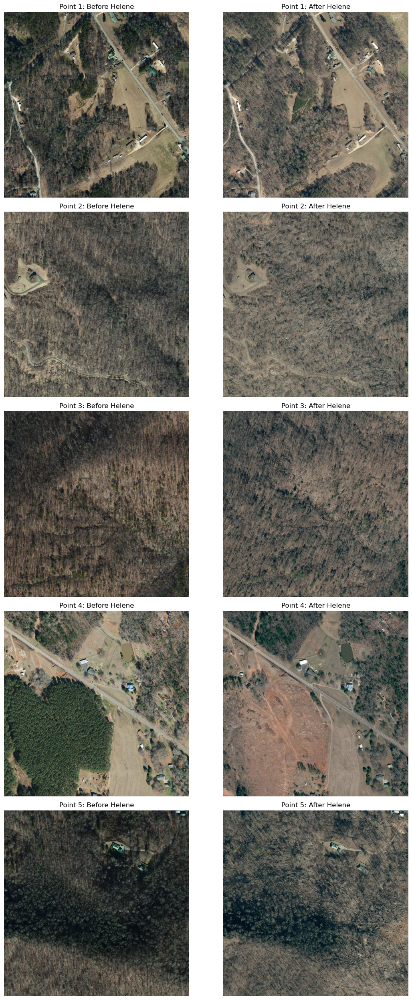

In [132]:
from pyproj import Transformer
import matplotlib.pyplot as plt

transformer = Transformer.from_crs(
    "EPSG:4326",
    "EPSG:32617",
    always_xy=True
)

fig, axes = plt.subplots(5, 2, figsize=(12, 25))

for i, (lon, lat) in enumerate(coordinates):

    x, y = transformer.transform(lon, lat)

    # 500 m x 500 m around each point
    bbox_point = [
        x - 250, y - 250,
        x + 250, y + 250
    ]

    pre_img = get_aerial_image(pre_url, bbox_point)
    post_img = get_aerial_image(service_url, bbox_point)

    axes[i, 0].imshow(pre_img)
    axes[i, 0].set_title(f"Point {i+1}: Before Helene")
    axes[i, 0].axis("off")

    axes[i, 1].imshow(post_img)
    axes[i, 1].set_title(f"Point {i+1}: After Helene")
    axes[i, 1].axis("off")

plt.tight_layout()
plt.show()

In [134]:
import ee
import geemap

# Before Hurricane Helene
pre_helene = (
    s2_all
    .filterDate("2024-09-01", "2024-09-26")
    .map(mask_clouds)
    .median()
    .clip(aoi)
)

# Immediately after Hurricane Helene
post_helene = (
    s2_all
    .filterDate("2024-10-01", "2024-10-25")
    .map(mask_clouds)
    .median()
    .clip(aoi)
)

# Calculate vegetation indices using your existing function
pre_indices = ee.Image(add_labeled_indices(pre_helene))
post_indices = ee.Image(add_labeled_indices(post_helene))

ndvi_change = (
    post_indices.select("NDVI")
    .subtract(pre_indices.select("NDVI"))
    .rename("NDVI_change")
)

nbr_change = (
    post_indices.select("NBR")
    .subtract(pre_indices.select("NBR"))
    .rename("NBR_change")
)

In [139]:
def mask_clouds_test(image):
    image = ee.Image(image)

    scl = image.select("SCL")

    clear = (
        scl.neq(1)
        .And(scl.neq(3))
        .And(scl.neq(8))
        .And(scl.neq(9))
        .And(scl.neq(10))
        .And(scl.neq(11))
    )

    return (
        image.select(["B2", "B3", "B4", "B8", "B11", "B12"])
        .updateMask(clear)
        .multiply(0.0001)
    )

In [137]:
# Load the original Sentinel-2 images
s2_clean = (
    ee.ImageCollection("COPERNICUS/S2_SR_HARMONIZED")
    .filterBounds(aoi)
    .filterDate("2024-09-01", "2024-10-25")
    .filter(ee.Filter.lt("CLOUDY_PIXEL_PERCENTAGE", 20))
)

print("Images found:", s2_clean.size().getInfo())
print("Bands:", ee.Image(s2_clean.first()).bandNames().getInfo())

Images found: 89
Bands: ['B1', 'B2', 'B3', 'B4', 'B5', 'B6', 'B7', 'B8', 'B8A', 'B9', 'B11', 'B12', 'AOT', 'WVP', 'SCL', 'TCI_R', 'TCI_G', 'TCI_B', 'MSK_CLDPRB', 'MSK_SNWPRB', 'QA10', 'QA20', 'QA60', 'MSK_CLASSI_OPAQUE', 'MSK_CLASSI_CIRRUS', 'MSK_CLASSI_SNOW_ICE']


In [140]:
pre_helene = (
    s2_clean
    .filterDate("2024-09-01", "2024-09-26")
    .map(mask_clouds_test)
    .median()
    .clip(aoi)
)

post_helene = (
    s2_clean
    .filterDate("2024-10-01", "2024-10-25")
    .map(mask_clouds_test)
    .median()
    .clip(aoi)
)

print("Pre bands:", pre_helene.bandNames().getInfo())
print("Post bands:", post_helene.bandNames().getInfo())

Pre bands: ['B2', 'B3', 'B4', 'B8', 'B11', 'B12']
Post bands: ['B2', 'B3', 'B4', 'B8', 'B11', 'B12']


In [141]:
pre_ndvi = pre_helene.normalizedDifference(
    ["B8", "B4"]
).rename("NDVI")

post_ndvi = post_helene.normalizedDifference(
    ["B8", "B4"]
).rename("NDVI")

ndvi_change = post_ndvi.subtract(pre_ndvi).rename("NDVI_change")

print(ndvi_change.bandNames().getInfo())

['NDVI_change']


In [142]:
pre_nbr = pre_helene.normalizedDifference(
    ["B8", "B12"]
).rename("NBR")

post_nbr = post_helene.normalizedDifference(
    ["B8", "B12"]
).rename("NBR")

nbr_change = post_nbr.subtract(pre_nbr).rename("NBR_change")

In [143]:
Map = geemap.Map()
Map.centerObject(sample_points, 10)

Map.addLayer(
    ndvi_change.updateMask(forest_mask),
    {
        "min": -0.4,
        "max": 0.4,
        "palette": ["red", "white", "green"]
    },
    "NDVI Change (Sep-Oct 2024)"
)

Map.addLayer(
    nbr_change.updateMask(forest_mask),
    {
        "min": -0.4,
        "max": 0.4,
        "palette": ["red", "white", "green"]
    },
    "NBR Change (Sep-Oct 2024)"
)

Map.addLayer(
    sample_points,
    {"color": "yellow"},
    "Five Aerial Image Locations"
)

Map

Map(center=[35.74059901563824, -81.97078036364304], controls=(WidgetControl(options=['position', 'transparent_…

In [144]:
changes = ndvi_change.addBands(nbr_change)

point_changes = changes.reduceRegions(
    collection=sample_points,
    reducer=ee.Reducer.mean(),
    scale=20
)

import pandas as pd

features = point_changes.getInfo()["features"]

rows = []

for i, feature in enumerate(features):
    props = feature["properties"]

    rows.append({
        "Point": i + 1,
        "NDVI_change": props.get("NDVI_change"),
        "NBR_change": props.get("NBR_change")
    })

df_changes = pd.DataFrame(rows)
display(df_changes)

,Point,NDVI_change,NBR_change
0,1,-0.008572,-0.030310
1,2,-0.288853,-0.512805
2,3,-0.042047,-0.328522
3,4,0.020216,-0.081924
4,5,-0.347148,-0.540987


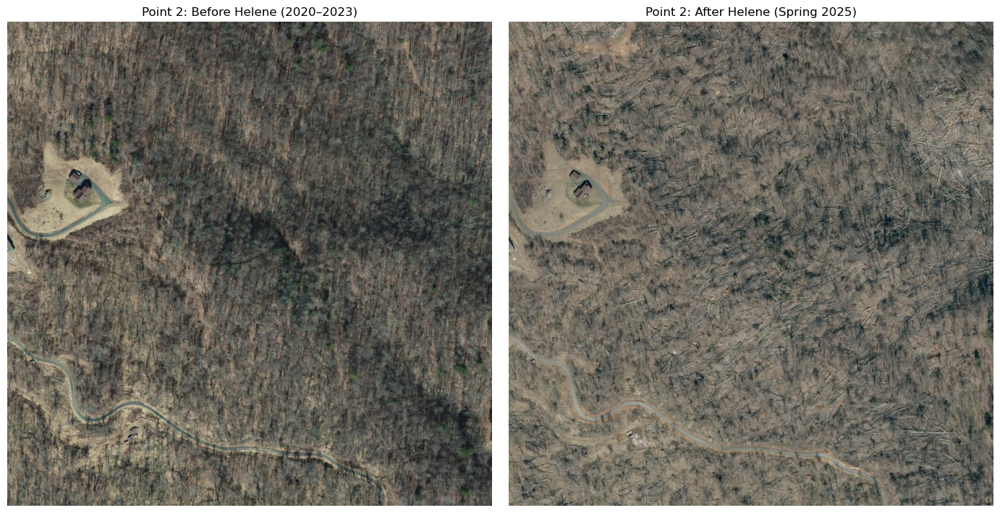

In [146]:
import matplotlib.pyplot as plt
from pyproj import Transformer

# Get Point 2 (index 1)
points_info = sample_points.getInfo()["features"]
lon, lat = points_info[1]["geometry"]["coordinates"]

# Convert coordinates to EPSG:32617
transformer = Transformer.from_crs(
    "EPSG:4326",
    "EPSG:32617",
    always_xy=True
)

x, y = transformer.transform(lon, lat)

# 500m x 500m area centered on Point 2
bbox = [x - 250, y - 250, x + 250, y + 250]

# Retrieve aerial photographs
pre_img = get_aerial_image(pre_url, bbox)
post_img = get_aerial_image(service_url, bbox)

# Display side by side
fig, axes = plt.subplots(1, 2, figsize=(14, 7))

axes[0].imshow(pre_img)
axes[0].set_title("Point 2: Before Helene (2020–2023)")
axes[0].axis("off")

axes[1].imshow(post_img)
axes[1].set_title("Point 2: After Helene (Spring 2025)")
axes[1].axis("off")

plt.tight_layout()
plt.show()

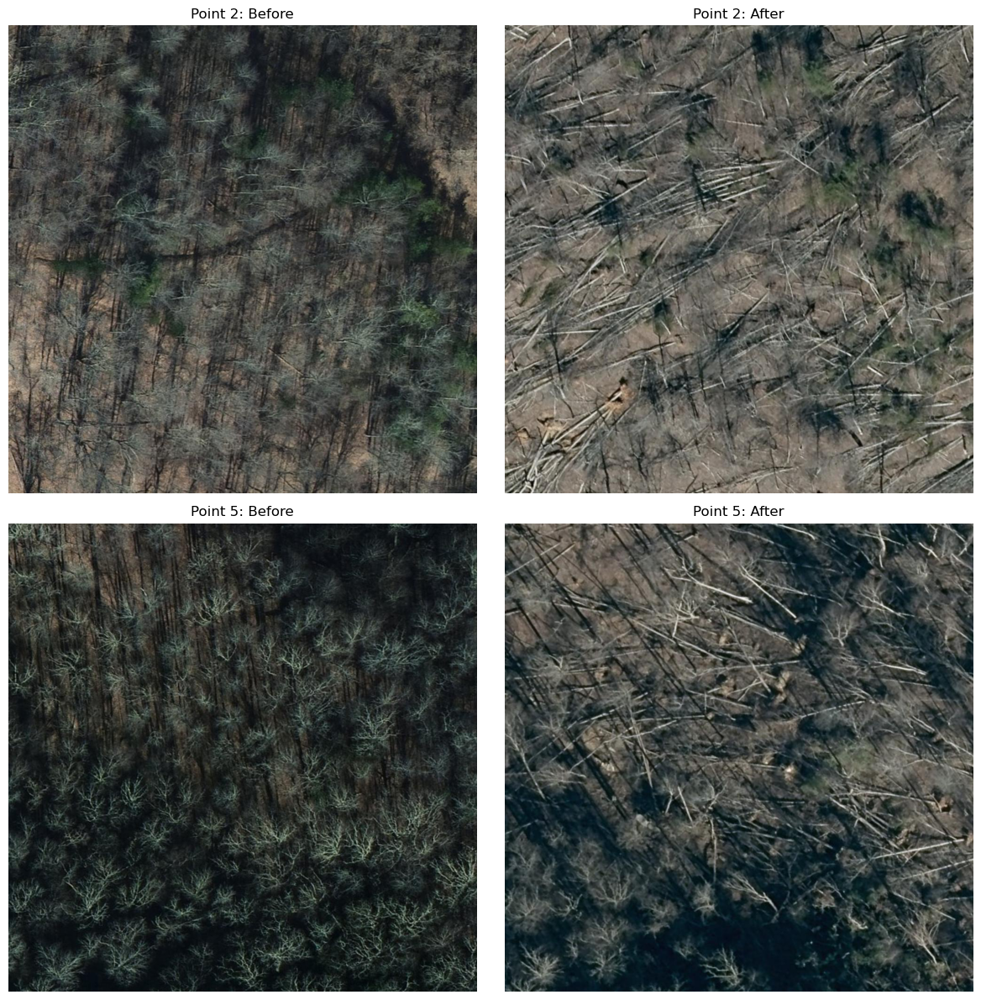

In [148]:
import matplotlib.pyplot as plt

points_info = sample_points.getInfo()["features"]

fig, axes = plt.subplots(2, 2, figsize=(12, 12))

for row, idx in enumerate([1, 4]):

    lon, lat = points_info[idx]["geometry"]["coordinates"]
    x, y = transformer.transform(lon, lat)

    # 100m x 100m around the point
    bbox = [x - 50, y - 50, x + 50, y + 50]

    pre_img = get_aerial_image(pre_url, bbox)
    post_img = get_aerial_image(service_url, bbox)

    axes[row, 0].imshow(pre_img)
    axes[row, 0].set_title(f"Point {idx+1}: Before")
    axes[row, 0].axis("off")

    axes[row, 1].imshow(post_img)
    axes[row, 1].set_title(f"Point {idx+1}: After")
    axes[row, 1].axis("off")

plt.tight_layout()
plt.show()

In [149]:
points_info = sample_points.getInfo()["features"]

for idx in [1, 4]:
    lon, lat = points_info[idx]["geometry"]["coordinates"]
    print(f"Point {idx + 1}: Latitude={lat}, Longitude={lon}")

Point 2: Latitude=36.02148065953892, Longitude=-82.19625925060964
Point 5: Latitude=35.97899083405158, Longitude=-82.15530474065694


In [151]:
# Identify potential vegetation loss
ndvi_loss = ndvi_change.lt(-0.15)
nbr_loss = nbr_change.lt(-0.20)

# Require both indices to indicate disturbance
loss_candidates = (
    ndvi_loss
    .And(nbr_loss)
    .updateMask(forest_mask)
    .rename("loss_candidate")
)

In [152]:
# Point 2
points = sample_points.toList(sample_points.size())
point2 = ee.Feature(points.get(1))

# Create a 100m x 100m square
region2 = point2.geometry().buffer(50).bounds()

print("Point 2 region created")

Point 2 region created


In [156]:
stats = loss_candidates.clip(region2).reduceRegion(
    reducer=ee.Reducer.frequencyHistogram(),
    geometry=region2,
    scale=10,
    maxPixels=10000
)

print(stats.getInfo())

{'loss_candidate': {'0': 2, '1': 121.01568627450982}}


In [158]:
hist = stats.getInfo()["loss_candidate"]

no_loss = hist.get("0", 0)
loss = hist.get("1", 0)

total = no_loss + loss

print(f"Potential loss: {loss / total * 100:.2f}%")
print(f"No detected loss: {no_loss / total * 100:.2f}%")

Potential loss: 98.37%
No detected loss: 1.63%


In [159]:
import ee

# 1 = Likely vegetation loss
loss = (
    ndvi_change.lte(-0.15)
    .And(nbr_change.lte(-0.20))
)

# 0 = Likely unchanged forest
stable = (
    ndvi_change.gte(-0.05)
    .And(nbr_change.gte(-0.05))
)

# Start with 255 = uncertain / excluded
labels = ee.Image.constant(255)

labels = (
    labels
    .where(stable, 0)
    .where(loss, 1)
    .updateMask(forest_mask)
    .updateMask(ndvi_change.mask())
    .updateMask(nbr_change.mask())
    .rename("label")
    .toUint8()
    .clip(aoi)
)

print("Label bands:", labels.bandNames().getInfo())

Label bands: ['label']


In [162]:
# 500m x 500m region around Point 2
region2_large = point2.geometry().buffer(250).bounds()

Map = geemap.Map()
Map.centerObject(point2, 15)

Map.addLayer(
    region2_large,
    {"color": "blue"},
    "Point 2 Training Region"
)

Map.addLayer(
    point2,
    {"color": "yellow"},
    "Point 2"
)

Map

Map(center=[36.02148065953892, -82.19625925060964], controls=(WidgetControl(options=['position', 'transparent_…

In [163]:
# 1 = Potential loss
loss = (
    ndvi_change.lte(-0.15)
    .And(nbr_change.lte(-0.20))
)

# 0 = Potential unchanged forest
stable = (
    ndvi_change.gte(-0.05)
    .And(nbr_change.gte(-0.05))
)

# 255 = Uncertain or unverified
candidate_labels = (
    ee.Image.constant(255)
    .where(stable, 0)
    .where(loss, 1)
    .updateMask(forest_mask)
    .updateMask(ndvi_change.mask())
    .updateMask(nbr_change.mask())
    .rename("candidate_label")
    .toUint8()
    .clip(region2_large)
)

In [164]:
Map = geemap.Map()
Map.centerObject(point2, 15)

Map.addLayer(
    candidate_labels.updateMask(candidate_labels.neq(255)),
    {
        "min": 0,
        "max": 1,
        "palette": ["green", "red"]
    },
    "Candidate Labels"
)

Map.addLayer(
    region2_large,
    {"color": "blue"},
    "Training Region"
)

Map

Map(center=[36.02148065953892, -82.19625925060964], controls=(WidgetControl(options=['position', 'transparent_…

In [165]:
projection = pre_helene.select("B4").projection().getInfo()

task = ee.batch.Export.image.toDrive(
    image=candidate_labels.unmask(255).toUint8(),
    description="Point2_Candidate_Labels",
    folder="Helene_Project",
    fileNamePrefix="point2_candidate_labels",
    region=region2_large,
    crs=projection["crs"],
    crsTransform=projection["transform"],
    maxPixels=1e8,
    fileFormat="GeoTIFF"
)

task.start()
print(task.status())

{'state': 'READY', 'description': 'Point2_Candidate_Labels', 'priority': 100, 'creation_timestamp_ms': 1793164946898, 'update_timestamp_ms': 1793164946898, 'start_timestamp_ms': 0, 'task_type': 'EXPORT_IMAGE', 'id': 'HY7QO24YF7RVTZ27PC5ZX6H2', 'name': 'projects/geospatialfinalproject/operations/HY7QO24YF7RVTZ27PC5ZX6H2'}


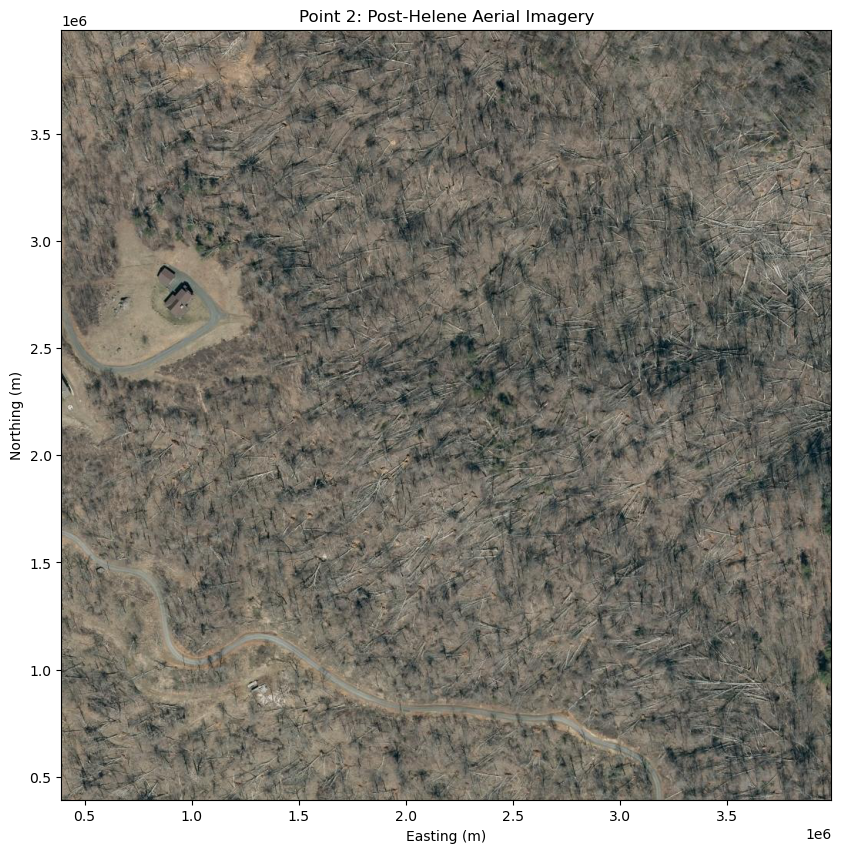

In [166]:
import matplotlib.pyplot as plt

# Point 2 coordinates
lon, lat = point2.geometry().coordinates().getInfo()
x, y = transformer.transform(lon, lat)

# 500m x 500m bounding box
bbox2_large = [x - 250, y - 250, x + 250, y + 250]

# Spring 2025 aerial imagery
post_aerial = get_aerial_image(service_url, bbox2_large)

plt.figure(figsize=(10, 10))
plt.imshow(post_aerial, extent=bbox2_large)
plt.title("Point 2: Post-Helene Aerial Imagery")
plt.xlabel("Easting (m)")
plt.ylabel("Northing (m)")
plt.show()

In [168]:
# Projection of the composite
print("Composite projection:")
print(pre_helene.select("B4").projection().getInfo())

# Projection of an original Sentinel-2 image
print("\nOriginal Sentinel-2 projection:")
print(
    ee.Image(s2_clean.first())
    .select("B4")
    .projection()
    .getInfo()
)

Composite projection:
{'type': 'Projection', 'crs': 'EPSG:4326', 'transform': [1, 0, 0, 0, 1, 0]}

Original Sentinel-2 projection:
{'type': 'Projection', 'crs': 'EPSG:32617', 'transform': [10, 0, 399960, 0, -10, 4000020]}


In [172]:
# Get the original Sentinel-2 10m grid
reference_image = ee.Image(s2_clean.first()).select("B4")

reference_projection = reference_image.projection().getInfo()

print(reference_projection)

{'type': 'Projection', 'crs': 'EPSG:32617', 'transform': [10, 0, 399960, 0, -10, 4000020]}


In [173]:
task = ee.batch.Export.image.toDrive(
    image=candidate_labels.unmask(255).toUint8(),
    description="Point2_Candidate_Labels_10m",
    folder="Helene_Project",
    fileNamePrefix="point2_candidate_labels_10m",
    region=region2_large,
    crs=reference_projection["crs"],
    crsTransform=reference_projection["transform"],
    maxPixels=1e8,
    fileFormat="GeoTIFF"
)

task.start()

print(task.status())

{'state': 'READY', 'description': 'Point2_Candidate_Labels_10m', 'priority': 100, 'creation_timestamp_ms': 1793165464105, 'update_timestamp_ms': 1793165464105, 'start_timestamp_ms': 0, 'task_type': 'EXPORT_IMAGE', 'id': 'VKKHUI5QHUMWWUBVTV3AKI2C', 'name': 'projects/geospatialfinalproject/operations/VKKHUI5QHUMWWUBVTV3AKI2C'}


In [178]:
print(task.status()["state"])

COMPLETED


In [180]:
import rasterio
import numpy as np
import matplotlib.pyplot as plt

with rasterio.open("point2_candidate_labels_10m.tif") as src:
    label_array = src.read(1)
    label_bounds = src.bounds
    label_crs = src.crs
    label_resolution = src.res

print("CRS:", label_crs)
print("Resolution:", label_resolution)
print("Label values:", np.unique(label_array, return_counts=True))

CRS: EPSG:32617
Resolution: (10.0, 10.0)
Label values: (array([  0,   1, 255], dtype=uint8), array([ 132, 2120,  400], dtype=int64))


In [181]:
import rasterio
import numpy as np
import matplotlib.pyplot as plt

with rasterio.open("point2_candidate_labels_10m.tif") as src:
    labels = src.read(1)
    bounds = src.bounds

    print("CRS:", src.crs)
    print("Resolution:", src.res)
    print("Shape:", src.shape)

print("Label counts:")
print(dict(zip(*np.unique(labels, return_counts=True))))

CRS: EPSG:32617
Resolution: (10.0, 10.0)
Shape: (51, 52)
Label counts:
{0: 132, 1: 2120, 255: 400}


In [182]:
bbox = [
    bounds.left,
    bounds.bottom,
    bounds.right,
    bounds.top
]

post_aerial = get_aerial_image(service_url, bbox)

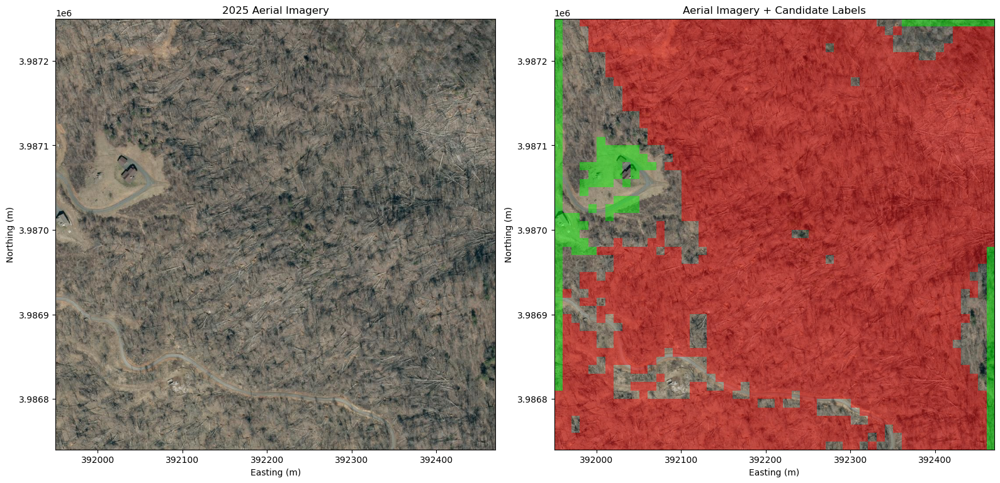

In [183]:
from matplotlib.colors import ListedColormap, BoundaryNorm

extent = [
    bounds.left,
    bounds.right,
    bounds.bottom,
    bounds.top
]

# Hide uncertain pixels
visible_labels = np.ma.masked_where(
    labels == 255,
    labels
)

cmap = ListedColormap(["lime", "red"])
cmap.set_bad(alpha=0)

fig, axes = plt.subplots(1, 2, figsize=(16, 8))

# Original aerial imagery
axes[0].imshow(post_aerial, extent=extent)
axes[0].set_title("2025 Aerial Imagery")

# Overlay candidate labels
axes[1].imshow(post_aerial, extent=extent)

axes[1].imshow(
    visible_labels,
    extent=extent,
    origin="upper",
    cmap=cmap,
    norm=BoundaryNorm([-0.5, 0.5, 1.5], 2),
    interpolation="nearest",
    alpha=0.45
)

axes[1].set_title("Aerial Imagery + Candidate Labels")

for ax in axes:
    ax.set_xlabel("Easting (m)")
    ax.set_ylabel("Northing (m)")

plt.tight_layout()
plt.show()

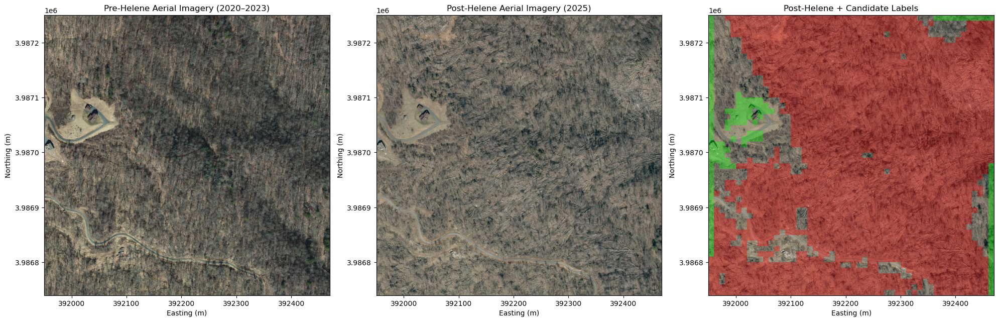

In [184]:
# Retrieve pre-hurricane aerial imagery
pre_aerial = get_aerial_image(pre_url, bbox)

fig, axes = plt.subplots(1, 3, figsize=(20, 7))

axes[0].imshow(pre_aerial, extent=extent)
axes[0].set_title("Pre-Helene Aerial Imagery (2020–2023)")

axes[1].imshow(post_aerial, extent=extent)
axes[1].set_title("Post-Helene Aerial Imagery (2025)")

axes[2].imshow(post_aerial, extent=extent)
axes[2].imshow(
    visible_labels,
    extent=extent,
    origin="upper",
    cmap=cmap,
    norm=BoundaryNorm([-0.5, 0.5, 1.5], 2),
    interpolation="nearest",
    alpha=0.35
)
axes[2].set_title("Post-Helene + Candidate Labels")

for ax in axes:
    ax.set_xlabel("Easting (m)")
    ax.set_ylabel("Northing (m)")

plt.tight_layout()
plt.show()

In [185]:
# Original forest mask
forest = (
    ee.ImageCollection("ESA/WorldCover/v200")
    .first()
    .select("Map")
    .eq(10)
)

# Remove forest pixels within 20m of nonforest
forest_interior = forest.focal_min(
    radius=20,
    units="meters"
)

# Apply to existing candidate labels
refined_labels = (
    candidate_labels
    .unmask(255)
    .where(forest_interior.Not(), 255)
    .rename("label")
    .toUint8()
    .clip(region2_large)
)

In [186]:
Map = geemap.Map()
Map.centerObject(point2, 15)

Map.addLayer(
    refined_labels.updateMask(refined_labels.neq(255)),
    {
        "min": 0,
        "max": 1,
        "palette": ["green", "red"]
    },
    "Refined Candidate Labels"
)

Map

Map(center=[36.02148065953892, -82.19625925060964], controls=(WidgetControl(options=['position', 'transparent_…

LOOK AT POINT 3 AERIAL IMAGERY

Point 3 (longitude, latitude): -81.7542790526632, 35.634892865997884


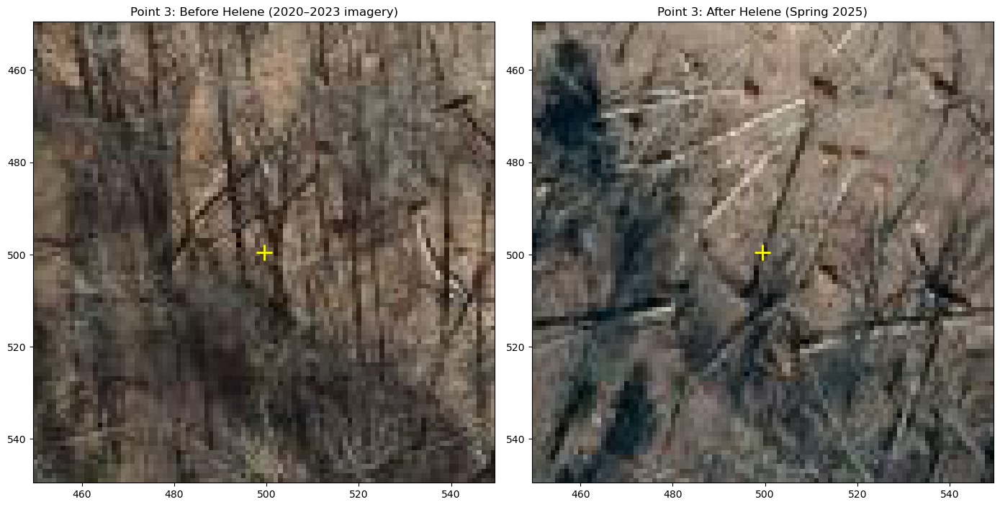

In [320]:
from pyproj import Transformer
import matplotlib.pyplot as plt

# Point 3 is at index 2 because Python starts counting at 0.
lon, lat = coordinates[2]
print(f"Point 3 (longitude, latitude): {lon}, {lat}")

transformer = Transformer.from_crs(
    "EPSG:4326", "EPSG:32617", always_xy=True
)
x, y = transformer.transform(lon, lat)

bbox = [x - 250, y - 250, x + 250, y + 250]

pre_img = get_aerial_image(pre_url, bbox)
post_img = get_aerial_image(service_url, bbox)

fig, axes = plt.subplots(1, 2, figsize=(14, 7))

axes[0].imshow(pre_img)
axes[0].set_title("Point 3: Before Helene (2020–2023 imagery)")

axes[1].imshow(post_img)
axes[1].set_title("Point 3: After Helene (Spring 2025)")



for ax, img in zip(axes, (pre_img, post_img)):
    width, height = img.size
    center_col = (width - 1) / 2
    center_row = (height - 1) / 2

    # Zoom to the central 50 m × 50 m of the 500 m × 500 m image.
    ax.set_xlim(center_col - width * 0.05, center_col + width * 0.05)
    ax.set_ylim(center_row + height * 0.05, center_row - height * 0.05)

    ax.plot(
        center_col, center_row,
        marker="+", color="yellow",
        markersize=16, markeredgewidth=2,
    )

fig.tight_layout()
plt.show()

Point 3 mask label: 255


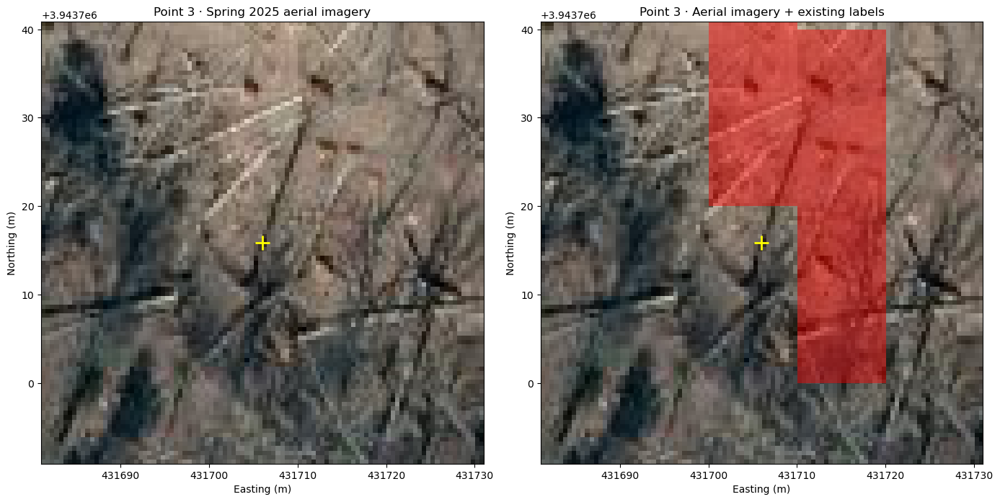

In [322]:
import math

import ee
import matplotlib.pyplot as plt
import numpy as np
import requests
from matplotlib.colors import BoundaryNorm, ListedColormap
from rasterio.io import MemoryFile
from rasterio.plot import plotting_extent

label_image = ee.Image(
    "projects/geospatialfinalproject/assets/"
    "Hurricane_Helene_BA/helene_binary_labels"
).select("label")

# Snap the download window to the saved mask's 10 m pixel grid.
grid = label_image.projection().getInfo()
dx, _, grid_x, _, dy, grid_y = grid["transform"]
xmin, ymin, xmax, ymax = bbox

col_start = math.floor((xmin - grid_x) / dx)
col_stop = math.ceil((xmax - grid_x) / dx)
row_start = math.floor((ymax - grid_y) / dy)
row_stop = math.ceil((ymin - grid_y) / dy)

left = grid_x + col_start * dx
top = grid_y + row_start * dy

url = label_image.unmask(255).toUint8().getDownloadURL({
    "crs": grid["crs"],
    "crs_transform": [dx, 0, left, 0, dy, top],
    "dimensions": [col_stop - col_start, row_stop - row_start],
    "format": "GEO_TIFF",
})

response = requests.get(url, timeout=60)
response.raise_for_status()

with MemoryFile(response.content) as memfile:
    with memfile.open() as src:
        point3_labels = src.read(1)
        label_extent = plotting_extent(point3_labels, src.transform)
        row, col = src.index(x, y)
        point3_value = int(point3_labels[row, col])

print("Point 3 mask label:", point3_value)

# Display the aerial image and mask using their own map extents.
aerial_extent = (xmin, xmax, ymin, ymax)
visible_labels = np.ma.masked_equal(point3_labels, 255)
cmap = ListedColormap(["lime", "red"])
cmap.set_bad(alpha=0)

fig, axes = plt.subplots(1, 2, figsize=(14, 7))

for ax in axes:
    ax.imshow(post_img, extent=aerial_extent, origin="upper")

axes[1].imshow(
    visible_labels,
    extent=label_extent,
    origin="upper",
    cmap=cmap,
    norm=BoundaryNorm([-0.5, 0.5, 1.5], 2),
    interpolation="nearest",
    alpha=0.45,
)

axes[0].set_title("Point 3 · Spring 2025 aerial imagery")
axes[1].set_title("Point 3 · Aerial imagery + existing labels")

for ax in axes:
    ax.plot(x, y, "+", color="yellow", markersize=14, markeredgewidth=2)
    ax.set(xlim=(x - 25, x + 25), ylim=(y - 25, y + 25))
    ax.set_xlabel("Easting (m)")
    ax.set_ylabel("Northing (m)")

fig.tight_layout()
plt.show()

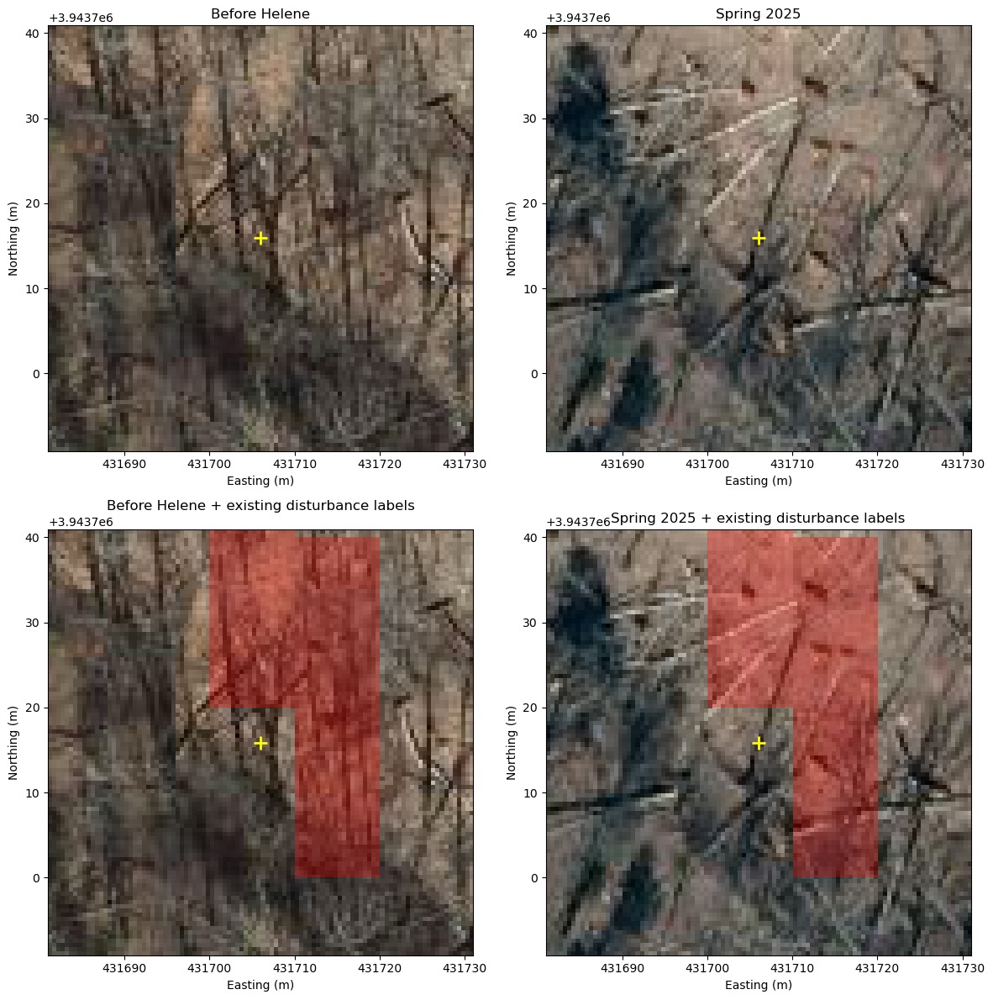

Point 3 center label: 255


In [323]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

# Show only cells labeled as likely disturbance.
disturbance = np.ma.masked_where(
    point3_labels != 1,
    np.ones_like(point3_labels)
)

red_cmap = ListedColormap(["red"])
red_cmap.set_bad(alpha=0)

xmin, ymin, xmax, ymax = bbox
aerial_extent = (xmin, xmax, ymin, ymax)

fig, axes = plt.subplots(2, 2, figsize=(12, 12))

for col, (img, title) in enumerate([
    (pre_img, "Before Helene"),
    (post_img, "Spring 2025"),
]):
    # Top row shows the original imagery.
    axes[0, col].imshow(
        img, extent=aerial_extent, origin="upper"
    )
    axes[0, col].set_title(title)

    # Bottom row shows identical label locations on each image.
    axes[1, col].imshow(
        img, extent=aerial_extent, origin="upper"
    )
    axes[1, col].imshow(
        disturbance,
        extent=label_extent,
        origin="upper",
        cmap=red_cmap,
        vmin=0,
        vmax=1,
        alpha=0.30,
        interpolation="nearest",
    )
    axes[1, col].set_title(f"{title} + existing disturbance labels")

for ax in axes.flat:
    ax.plot(
        x, y, "+",
        color="yellow", markersize=12, markeredgewidth=2
    )
    ax.set_xlim(x - 25, x + 25)
    ax.set_ylim(y - 25, y + 25)
    ax.set_xlabel("Easting (m)")
    ax.set_ylabel("Northing (m)")

fig.tight_layout()
plt.show()

print("Point 3 center label:", point3_value)

Point 5 center label: 1


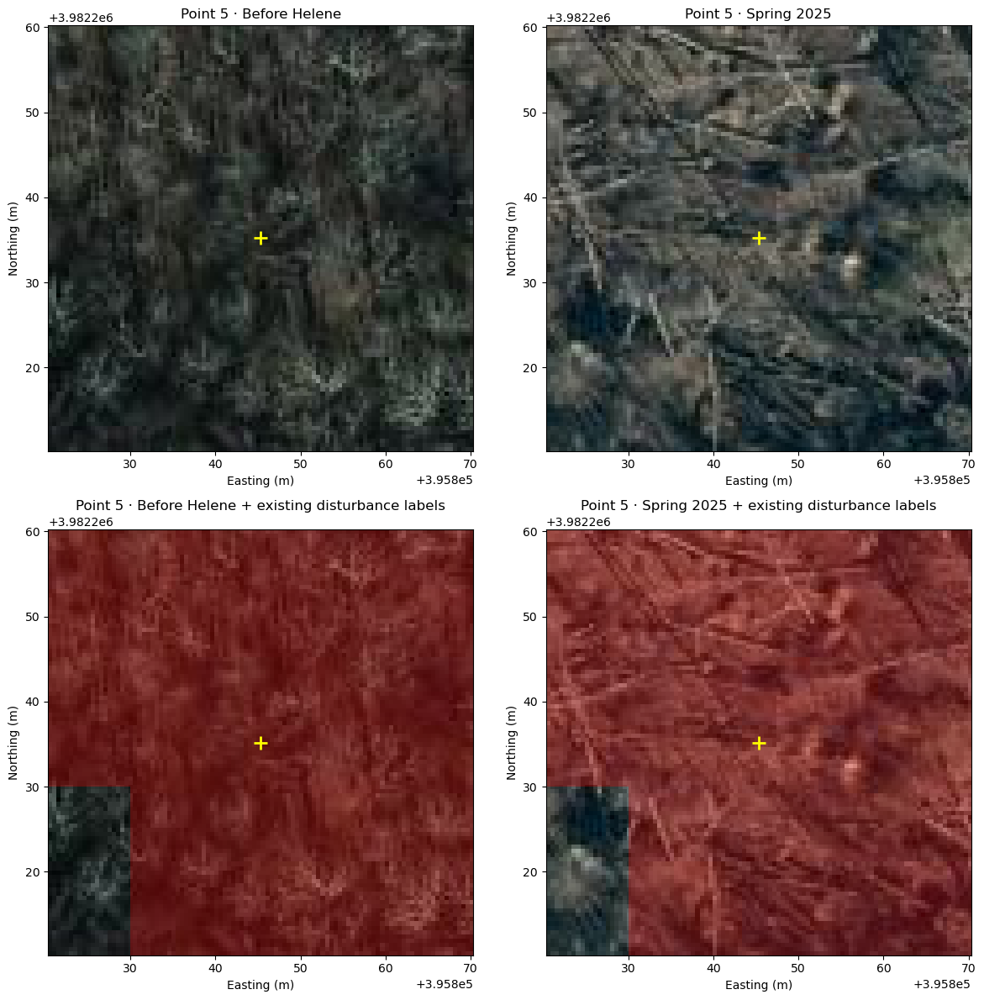

In [326]:
# Point 5
lon, lat = coordinates[4]
x, y = transformer.transform(lon, lat)

bbox = [x - 250, y - 250, x + 250, y + 250]
pre_img = get_aerial_image(pre_url, bbox)
post_img = get_aerial_image(service_url, bbox)

# Existing full-area labels
label_image = ee.Image(
    "projects/geospatialfinalproject/assets/"
    "Hurricane_Helene_BA/helene_binary_labels"
).select("label")

grid = label_image.projection().getInfo()
dx, _, grid_x, _, dy, grid_y = grid["transform"]
xmin, ymin, xmax, ymax = bbox

col_start = math.floor((xmin - grid_x) / dx)
col_stop = math.ceil((xmax - grid_x) / dx)
row_start = math.floor((ymax - grid_y) / dy)
row_stop = math.ceil((ymin - grid_y) / dy)

left = grid_x + col_start * dx
top = grid_y + row_start * dy

url = label_image.unmask(255).toUint8().getDownloadURL({
    "crs": grid["crs"],
    "crs_transform": [dx, 0, left, 0, dy, top],
    "dimensions": [col_stop - col_start, row_stop - row_start],
    "format": "GEO_TIFF",
})

response = requests.get(url, timeout=60)
response.raise_for_status()

with MemoryFile(response.content) as memfile:
    with memfile.open() as src:
        point5_labels = src.read(1)
        label_extent = plotting_extent(point5_labels, src.transform)
        row, col = src.index(x, y)
        point5_value = int(point5_labels[row, col])

print("Point 5 center label:", point5_value)

# Display only cells flagged as disturbance.
disturbance = np.ma.masked_where(
    point5_labels != 1,
    np.ones_like(point5_labels)
)

red_cmap = ListedColormap(["red"])
red_cmap.set_bad(alpha=0)

aerial_extent = (xmin, xmax, ymin, ymax)
fig, axes = plt.subplots(2, 2, figsize=(12, 12))

for column, (img, title) in enumerate([
    (pre_img, "Before Helene"),
    (post_img, "Spring 2025"),
]):
    axes[0, column].imshow(
        img, extent=aerial_extent, origin="upper"
    )
    axes[0, column].set_title(f"Point 5 · {title}")

    axes[1, column].imshow(
        img, extent=aerial_extent, origin="upper"
    )
    axes[1, column].imshow(
        disturbance,
        extent=label_extent,
        origin="upper",
        cmap=red_cmap,
        vmin=0,
        vmax=1,
        alpha=0.30,
        interpolation="nearest",
    )
    axes[1, column].set_title(
        f"Point 5 · {title} + existing disturbance labels"
    )

for ax in axes.flat:
    ax.plot(
        x, y, "+",
        color="yellow", markersize=12, markeredgewidth=2
    )
    ax.set_xlim(x - 25, x + 25)
    ax.set_ylim(y - 25, y + 25)
    ax.set_xlabel("Easting (m)")
    ax.set_ylabel("Northing (m)")

fig.tight_layout()
plt.show()

EXPORTING REFINED LABELS FOR POINT 2

In [187]:
task = ee.batch.Export.image.toDrive(
    image=refined_labels,
    description="Point2_Refined_Labels",
    folder="Helene_Project",
    fileNamePrefix="point2_refined_labels_10m",
    region=region2_large,
    crs=reference_projection["crs"],
    crsTransform=reference_projection["transform"],
    maxPixels=1e8,
    fileFormat="GeoTIFF"
)

task.start()
print(task.status()["state"])

READY


In [188]:
# Apply the same rules across Western NC
all_refined_labels = (
    ee.Image.constant(255)
    .where(stable, 0)
    .where(loss, 1)
    .where(forest_interior.Not(), 255)
    .updateMask(ndvi_change.mask())
    .updateMask(nbr_change.mask())
    .rename("label")
    .unmask(255)
    .toUint8()
    .clip(aoi)
)

In [189]:
all_task = ee.batch.Export.image.toDrive(
    image=all_refined_labels,
    description="Helene_All_Refined_Labels",
    folder="Helene_Project",
    fileNamePrefix="helene_all_refined_labels_10m",
    region=aoi,
    crs=reference_projection["crs"],
    crsTransform=reference_projection["transform"],
    maxPixels=1e10,
    fileFormat="GeoTIFF"
)

all_task.start()
print(all_task.status()["state"])

READY


In [190]:
# Compare original and refined labels
original = candidate_labels.unmask(255)
refined = refined_labels.unmask(255)

changed_pixels = original.neq(refined)

# Count changed pixels
changes = changed_pixels.reduceRegion(
    reducer=ee.Reducer.sum(),
    geometry=region2_large,
    crs=reference_projection["crs"],
    crsTransform=reference_projection["transform"],
    maxPixels=1e7
)

print("Number of changed pixels:", changes.getInfo())

Number of changed pixels: {'candidate_label': 35.52549019607843}


In [191]:
# Create refined candidate labels across the full study area
all_refined_labels = (
    ee.Image.constant(255)
    .where(stable, 0)
    .where(loss, 1)
    .where(forest_interior.Not(), 255)
    .updateMask(ndvi_change.mask())
    .updateMask(nbr_change.mask())
    .rename("label")
    .unmask(255)
    .toUint8()
    .clip(aoi)
)

print("Full study area labels created.")

Full study area labels created.


In [192]:
Map = geemap.Map()
Map.centerObject(aoi, 9)

Map.addLayer(
    all_refined_labels.updateMask(all_refined_labels.neq(255)),
    {
        "min": 0,
        "max": 1,
        "palette": ["green", "red"]
    },
    "Western NC Vegetation Loss Labels"
)

Map

Map(center=[35.477676487653866, -82.78681753304508], controls=(WidgetControl(options=['position', 'transparent…

# Before and After composites: 

In [193]:
composite_collection = ee.ImageCollection.fromImages(all_composites)

print(
    composite_collection.first().propertyNames().getInfo()
)

['system:time_start', 'scene_count', 'month', 'system:footprint', 'system:index', 'system:bands', 'system:band_names']


In [199]:
def add_indices(image):
    ndvi = image.normalizedDifference(
        ["B8", "B4"]
    ).rename("NDVI")

    ndmi = image.normalizedDifference(
        ["B8", "B11"]
    ).rename("NDMI")

    nbr = image.normalizedDifference(
        ["B8", "B12"]
    ).rename("NBR")

    return image.addBands([ndvi, ndmi, nbr])

In [200]:
pre_features = add_indices(pre_helene)
post_features = add_indices(post_helene)

In [201]:
bands = [
    "B2", "B3", "B4",
    "B8", "B11", "B12",
    "NDVI", "NDMI", "NBR"
]

pre_stack = pre_features.select(
    bands,
    [f"pre_{b}" for b in bands]
)

post_stack = post_features.select(
    bands,
    [f"post_{b}" for b in bands]
)

stacked_image = pre_stack.addBands(post_stack)

print("Total bands:", stacked_image.bandNames().size().getInfo())

Total bands: 18


In [202]:
ndvi_change = (
    post_features.select("NDVI")
    .subtract(pre_features.select("NDVI"))
    .rename("NDVI_change")
)

ndmi_change = (
    post_features.select("NDMI")
    .subtract(pre_features.select("NDMI"))
    .rename("NDMI_change")
)

nbr_change = (
    post_features.select("NBR")
    .subtract(pre_features.select("NBR"))
    .rename("NBR_change")
)

stacked_image = stacked_image.addBands([
    ndvi_change,
    ndmi_change,
    nbr_change
])

print("Total bands:", stacked_image.bandNames().size().getInfo())

Total bands: 21


In [203]:
print("Input bands:", stacked_image.bandNames().size().getInfo())

print("Label bands:", all_refined_labels.bandNames().getInfo())

Input bands: 21
Label bands: ['label']


Obtain Tiles:

In [209]:
import ee
import math

# Fixed Sentinel-2 export grid
crs = "EPSG:32617"
transform = [10, 0, 399960, 0, -10, 4000020]

# Convert the study boundary into the projected coordinate system
utm = ee.Projection(crs)

# aoi is already an ee.Geometry
bounds = aoi.transform(utm, 1).bounds(1, utm)

coords = bounds.coordinates().getInfo()[0]

xmin = min(p[0] for p in coords)
xmax = max(p[0] for p in coords)
ymin = min(p[1] for p in coords)
ymax = max(p[1] for p in coords)

# 10 km x 10 km tiles
tile_size = 10000

# Align tile boundaries to the Sentinel-2 grid
x_origin = transform[2]
y_origin = transform[5]

xmin_aligned = x_origin + math.floor(
    (xmin - x_origin) / tile_size
) * tile_size

ymin_aligned = y_origin + math.floor(
    (ymin - y_origin) / tile_size
) * tile_size

xmax_aligned = x_origin + math.ceil(
    (xmax - x_origin) / tile_size
) * tile_size

ymax_aligned = y_origin + math.ceil(
    (ymax - y_origin) / tile_size
) * tile_size

# Generate candidate tiles
tiles = []

for x in range(int(xmin_aligned), int(xmax_aligned), tile_size):
    for y in range(int(ymin_aligned), int(ymax_aligned), tile_size):

        tile = ee.Geometry.Rectangle(
            [x, y, x + tile_size, y + tile_size],
            proj=utm,
            geodesic=False
        )

        tiles.append(tile)

print("Candidate tiles:", len(tiles))

Candidate tiles: 392


In [211]:
# Convert candidate tiles into a FeatureCollection
tile_features = [
    ee.Feature(tile, {"tile_id": i})
    for i, tile in enumerate(tiles)
]

tile_collection = ee.FeatureCollection(tile_features)

# Filter tiles intersecting the study boundary
valid_collection = tile_collection.filterBounds(aoi)

# Get the number of valid tiles
print("Candidate tiles:", len(tiles))
print("Tiles intersecting study area:", valid_collection.size().getInfo())

Candidate tiles: 392
Tiles intersecting study area: 232


In [212]:
tile_list = valid_collection.toList(
    valid_collection.size()
)

valid_tiles = [
    ee.Feature(tile_list.get(i)).geometry()
    for i in range(232)
]

print("Valid tiles ready:", len(valid_tiles))

Valid tiles ready: 232


In [213]:
# September–October 21-band Sentinel-2 stack
full_inputs = stacked_image.clip(aoi)

# Binary labels from our Point 2 labeling method
full_labels = all_refined_labels.clip(aoi)

# Preserve missing-data pixels with a sentinel value
full_inputs = full_inputs.unmask(-9999).toFloat()

# Keep uncertain and excluded labels as 255
full_labels = full_labels.unmask(255).toUint8()

print("CNN inputs and labels ready!")

CNN inputs and labels ready!


In [294]:
import ee

folder = "projects/geospatialfinalproject/assets/Hurricane_Helene_BA"

# Export the 21-band Sentinel-2 input stack
input_task = ee.batch.Export.image.toAsset(
    image=full_inputs,
    description="helene_21band_inputs",
    assetId=f"{folder}/helene_21band_inputs",
    region=aoi,
    crs=crs,
    crsTransform=transform,
    maxPixels=1e13
)

input_task.start()

# Export your binary ground-truth labels
label_task = ee.batch.Export.image.toAsset(
    image=full_labels,
    description="helene_binary_labels",
    assetId=f"{folder}/helene_binary_labels",
    region=aoi,
    crs=crs,
    crsTransform=transform,
    maxPixels=1e13
)

label_task.start()

print("Input task:", input_task.id)
print("Label task:", label_task.id)

Input task: ZXE4KWL3DG5SS6J3QQGC2476
Label task: YDXPEI5LFSOVT6AEHSOV6RZH


In [297]:
for name, task in [
    ("21-band inputs", input_task),
    ("Binary labels", label_task)
]:
    status = task.status()

    print(name, ":", status["state"])

    if status["state"] == "FAILED":
        print("Error:", status.get("error_message"))

21-band inputs : COMPLETED
Binary labels : COMPLETED


In [298]:
folder = "projects/geospatialfinalproject/assets/Hurricane_Helene_BA"

saved_inputs = ee.Image(f"{folder}/helene_21band_inputs")
saved_labels = ee.Image(f"{folder}/helene_binary_labels")

print("Input bands:", saved_inputs.bandNames().getInfo())
print("Label bands:", saved_labels.bandNames().getInfo())

Input bands: ['pre_B2', 'pre_B3', 'pre_B4', 'pre_B8', 'pre_B11', 'pre_B12', 'pre_NDVI', 'pre_NDMI', 'pre_NBR', 'post_B2', 'post_B3', 'post_B4', 'post_B8', 'post_B11', 'post_B12', 'post_NDVI', 'post_NDMI', 'post_NBR', 'NDVI_change', 'NDMI_change', 'NBR_change']
Label bands: ['label']


In [ ]:
saved_inputs = ee.Image(
    f"{folder}/helene_21band_inputs"
)

saved_labels = ee.Image(
    f"{folder}/helene_binary_labels"
)

print("Input bands:", saved_inputs.bandNames().getInfo())
print("Label bands:", saved_labels.bandNames().getInfo())

In [293]:
import ee

folder = "projects/geospatialfinalproject/assets/Hurricane_Helene_BA"

print(ee.data.getAsset(folder))

{'type': 'FOLDER', 'name': 'projects/geospatialfinalproject/assets/Hurricane_Helene_BA', 'id': 'projects/geospatialfinalproject/assets/Hurricane_Helene_BA'}


In [214]:
export_tasks = []

for i, tile in enumerate(valid_tiles[:3]):

    tile_id = f"tile_{i:03d}"

    input_task = ee.batch.Export.image.toDrive(
        image=full_inputs.clip(tile),
        description=f"{tile_id}_inputs",
        folder="Helene_CNN",
        fileNamePrefix=f"{tile_id}_inputs",
        region=tile,
        crs=crs,
        crsTransform=transform,
        maxPixels=1e10,
        fileFormat="GeoTIFF"
    )

    label_task = ee.batch.Export.image.toDrive(
        image=full_labels.clip(tile).unmask(255).toUint8(),
        description=f"{tile_id}_labels",
        folder="Helene_CNN",
        fileNamePrefix=f"{tile_id}_labels",
        region=tile,
        crs=crs,
        crsTransform=transform,
        maxPixels=1e10,
        fileFormat="GeoTIFF"
    )

    input_task.start()
    label_task.start()

    export_tasks.append((tile_id, input_task, label_task))

print("Started exports for 3 tiles.")

Started exports for 3 tiles.


In [220]:
# Count forest pixels in this tile
tile = valid_tiles[0]

forest_count = forest_interior.clip(tile).reduceRegion(
    reducer=ee.Reducer.sum(),
    geometry=tile,
    scale=10,
    maxPixels=1e8
)

print("Forest pixels:", forest_count.getInfo())

# Count labeled pixels
labeled_count = all_refined_labels.clip(tile).neq(255).reduceRegion(
    reducer=ee.Reducer.sum(),
    geometry=tile,
    scale=10,
    maxPixels=1e8
)

print("Labeled pixels:", labeled_count.getInfo())

Forest pixels: {'Map': 922405.9294117654}
Labeled pixels: {'label': 44258.92941176469}


In [227]:
# Original CNN inputs and labels
full_inputs = stacked_image.toFloat()
full_labels = all_refined_labels.toUint8()

# Expand the image footprint without blending
tile = valid_tiles[0]

tile_inputs = (
    full_inputs
    .unmask(-9999, sameFootprint=False)
    .clip(tile)
)

tile_labels = (
    full_labels
    .unmask(255, sameFootprint=False)
    .clip(tile)
)

In [228]:
counts = tile_labels.reduceRegion(
    reducer=ee.Reducer.frequencyHistogram(),
    geometry=tile,
    crs="EPSG:32617",
    scale=10,
    maxPixels=1e8,
    tileScale=4
)

print(counts.getInfo())

{'label': {'0': 35548.4, '1': 192.15686274509804, '255': 963941.2901960786}}


In [229]:
tile = valid_tiles[0]

# Preserve original labels and fill masked pixels with 255
tile_labels = (
    all_refined_labels
    .unmask(255, sameFootprint=False)
    .toUint8()
)

# Use the exact tile bounds and dimensions
task = ee.batch.Export.image.toDrive(
    image=tile_labels,
    description="tile_000_labels_test",
    folder="Helene_CNN",
    fileNamePrefix="tile_000_labels_test",
    region=tile,
    crs="EPSG:32617",
    dimensions="1000x1000",
    maxPixels=1e10,
    fileFormat="GeoTIFF"
)

task.start()
print("Started label test export.")

Started label test export.


In [230]:
import rasterio
import numpy as np

with rasterio.open("tile_000_labels_test.tif") as src:
    labels = src.read(1)

    print("Shape:", labels.shape)
    print("Bounds:", src.bounds)
    print("Transform:", src.transform)

    values, counts = np.unique(labels, return_counts=True)

    for value, count in zip(values, counts):
        print(f"Label {value}: {count:,}")

Shape: (1000, 1000)
Bounds: BoundingBox(left=189960.0, bottom=3870020.0, right=199960.0, top=3880020.0)
Transform: | 10.00, 0.00, 189960.00|
| 0.00,-10.00, 3880020.00|
| 0.00, 0.00, 1.00|
Label 0: 35,703
Label 1: 193
Label 255: 964,104


In [231]:
tile = valid_tiles[0]

tile_inputs = (
    stacked_image
    .unmask(-9999, sameFootprint=False)
    .toFloat()
)

task = ee.batch.Export.image.toDrive(
    image=tile_inputs,
    description="tile_000_inputs_test",
    folder="Helene_CNN",
    fileNamePrefix="tile_000_inputs_test",
    region=tile,
    crs="EPSG:32617",
    dimensions="1000x1000",
    maxPixels=1e10,
    fileFormat="GeoTIFF"
)

task.start()
print("Started input test export.")

Started input test export.


In [233]:
import rasterio
import numpy as np

with rasterio.open("tile_000_inputs_test.tif") as img, \
     rasterio.open("tile_000_labels_test.tif") as lbl:

    inputs = img.read()
    labels = lbl.read(1)

    print("Input shape:", inputs.shape)
    print("Label shape:", labels.shape)

    print("Same bounds:", img.bounds == lbl.bounds)
    print("Same CRS:", img.crs == lbl.crs)
    print("Same transform:", img.transform == lbl.transform)

    valid_inputs = np.all(
        np.isfinite(inputs) & (inputs != -9999),
        axis=0
    )

    print("Pixels with valid inputs:", valid_inputs.sum())
    print("Pixels with usable labels and valid inputs:",
          np.sum((labels != 255) & valid_inputs))

    print("Vegetation-loss pixels with valid inputs:",
          np.sum((labels == 1) & valid_inputs))

Input shape: (21, 1000, 1000)
Label shape: (1000, 1000)
Same bounds: True
Same CRS: True
Same transform: True
Pixels with valid inputs: 97595
Pixels with usable labels and valid inputs: 35896
Vegetation-loss pixels with valid inputs: 193


In [234]:
import ee
import pandas as pd

results = []

for i in range(10):
    tile = valid_tiles[i]

    counts = all_refined_labels.reduceRegion(
        reducer=ee.Reducer.frequencyHistogram(),
        geometry=tile,
        crs="EPSG:32617",
        scale=10,
        maxPixels=1e8,
        tileScale=4
    ).getInfo()

    hist = counts.get("label", {})

    unchanged = hist.get("0", 0)
    loss = hist.get("1", 0)
    excluded = hist.get("255", 0)

    usable = unchanged + loss

    results.append({
        "Tile": f"tile_{i:03d}",
        "Unchanged": round(unchanged),
        "Loss": round(loss),
        "Excluded": round(excluded),
        "Usable": round(usable),
        "Loss %": round(loss / usable * 100, 2) if usable > 0 else 0
    })

df = pd.DataFrame(results)

display(df)

,Tile,Unchanged,Loss,Excluded,Usable,Loss %
0,tile_000,35548,192,61536,35741,0.54
1,tile_001,119967,220,82775,120187,0.18
2,tile_002,30694,37,29134,30731,0.12
3,tile_003,169897,834,181469,170731,0.49
4,tile_004,557040,435,442525,557475,0.08
5,tile_005,600764,417,397493,601181,0.07
6,tile_006,413953,65,108333,414017,0.02
7,tile_007,147338,1110,241944,148449,0.75
8,tile_008,468161,521,531318,468682,0.11
9,tile_009,498671,953,500376,499624,0.19


In [ ]:
df_sorted = df.sort_values(
    by="Loss",
    ascending=False
)

display(df_sorted)

In [236]:
import ee
import pandas as pd

def get_tile_distribution(feature):
    hist = ee.Dictionary(
        all_refined_labels.reduceRegion(
            reducer=ee.Reducer.frequencyHistogram(),
            geometry=feature.geometry(),
            crs="EPSG:32617",
            scale=10,
            maxPixels=1e8,
            tileScale=4
        ).get("label")
    )

    unchanged = ee.Number(hist.get("0", 0))
    loss = ee.Number(hist.get("1", 0))
    excluded = ee.Number(hist.get("255", 0))
    usable = unchanged.add(loss)

    loss_pct = ee.Algorithms.If(
        usable.gt(0),
        loss.divide(usable).multiply(100),
        0
    )

    return feature.set({
        "unchanged": unchanged,
        "loss": loss,
        "excluded": excluded,
        "usable": usable,
        "loss_pct": loss_pct
    })

# Calculate statistics for all 232 tiles
tile_stats = valid_collection.map(get_tile_distribution)

In [237]:
features = tile_stats.getInfo()["features"]

data = []

for feature in features:
    p = feature["properties"]

    data.append({
        "Tile": f"tile_{p['tile_id']:03d}",
        "Unchanged": round(p["unchanged"]),
        "Loss": round(p["loss"]),
        "Excluded": round(p["excluded"]),
        "Usable": round(p["usable"]),
        "Loss %": round(p["loss_pct"], 2)
    })

df_all = pd.DataFrame(data)

print("Total tiles:", len(df_all))
display(df_all.head(10))

Total tiles: 232


,Tile,Unchanged,Loss,Excluded,Usable,Loss %
0,tile_000,35548,192,61536,35741,0.54
1,tile_001,119967,220,82775,120187,0.18
2,tile_002,30694,37,29134,30731,0.12
3,tile_014,169897,834,181469,170731,0.49
4,tile_015,557040,435,442525,557475,0.08
5,tile_016,600764,417,397493,601181,0.07
6,tile_017,413953,65,108333,414017,0.02
7,tile_028,147338,1110,241944,148449,0.75
8,tile_029,468161,521,531318,468682,0.11
9,tile_030,498671,953,500376,499624,0.19


In [238]:
df_sorted = df_all.sort_values(
    by="Loss",
    ascending=False
)

display(df_sorted.head(20))

,Tile,Unchanged,Loss,Excluded,Usable,Loss %
168,tile_278,41233,398177,474387,439410,90.62
180,tile_292,34975,323992,554675,358968,90.26
179,tile_291,36366,283350,680079,319716,88.63
142,tile_245,183405,228720,587875,412125,55.50
190,tile_304,41943,223740,621396,265683,84.21
178,tile_290,63960,213346,722367,277307,76.94
153,tile_260,95349,207740,696842,303090,68.54
189,tile_303,168317,182363,649153,350680,52.00
177,tile_289,96051,174788,728832,270839,64.54
201,tile_318,111881,174638,527414,286519,60.95


In [239]:
print("Total tiles:", len(df_all))

print("Tiles containing vegetation loss:",
      (df_all["Loss"] > 0).sum())

print("Tiles with more than 1000 loss pixels:",
      (df_all["Loss"] > 1000).sum())

print("Tiles with more than 5000 loss pixels:",
      (df_all["Loss"] > 5000).sum())

print("Total vegetation-loss pixels:",
      df_all["Loss"].sum())

Total tiles: 232
Tiles containing vegetation loss: 230
Tiles with more than 1000 loss pixels: 194
Tiles with more than 5000 loss pixels: 144
Total vegetation-loss pixels: 6898668


In [240]:
df_all.to_csv("helene_tile_label_distributions.csv", index=False)

In [241]:
total_unchanged = df_all["Unchanged"].sum()
total_loss = df_all["Loss"].sum()
total_usable = df_all["Usable"].sum()

print(f"Unchanged pixels: {total_unchanged:,}")
print(f"Loss pixels: {total_loss:,}")
print(f"Usable pixels: {total_usable:,}")

print(f"Overall loss percentage: {total_loss / total_usable * 100:.2f}%")

Unchanged pixels: 53,475,445
Loss pixels: 6,898,668
Usable pixels: 60,374,115
Overall loss percentage: 11.43%


In [243]:
# CNN inputs: 21 Sentinel-2 bands
export_inputs = (
    stacked_image
    .unmask(-9999, sameFootprint=False)
    .toFloat()
)

# CNN labels: 0, 1, or 255
export_labels = (
    all_refined_labels
    .unmask(255, sameFootprint=False)
    .toUint8()
)

print("Input bands:", export_inputs.bandNames().getInfo())
print("Number of tiles:", len(valid_tiles))

Input bands: ['pre_B2', 'pre_B3', 'pre_B4', 'pre_B8', 'pre_B11', 'pre_B12', 'pre_NDVI', 'pre_NDMI', 'pre_NBR', 'post_B2', 'post_B3', 'post_B4', 'post_B8', 'post_B11', 'post_B12', 'post_NDVI', 'post_NDMI', 'post_NBR', 'NDVI_change', 'NDMI_change', 'NBR_change']
Number of tiles: 232


In [249]:
%pip install geedim


  Obtaining dependency information for geedim from https://files.pythonhosted.org/packages/ea/77/d3df02afb15ce5e3d8823a0656372216234137fbf6707e0b702d1f6379fa/geedim-2.0.1-py3-none-any.whl.metadata
  Obtaining dependency information for tabulate>=0.9 from https://files.pythonhosted.org/packages/99/55/db07de81b5c630da5cbf5c7df646580ca26dfaefa593667fc6f2fe016d2e/tabulate-0.10.0-py3-none-any.whl.metadata
     ---------------------------------------- 0.0/40.8 kB ? eta -:--:--
     ---------------------------------------- 40.8/40.8 kB 2.0 MB/s eta 0:00:00
   ---------------------------------------- 0.0/73.4 kB ? eta -:--:--
   ---------------------------------------  71.7/73.4 kB 3.8 MB/s eta 0:00:01
   ---------------------------------------- 73.4/73.4 kB 2.0 MB/s eta 0:00:00
  Attempting uninstall: tabulate
    Found existing installation: tabulate 0.8.10
    Uninstalling tabulate-0.8.10:
      Successfully uninstalled tabulate-0.8.10


Splitting train/test/val and exported to Google Earth Engine Asset database

SPLIT DATA TRAIN/TEST/VAL

In [253]:
import ee
import pandas as pd
import numpy as np

# Use the same ordering as your export_tile(i) function
tile_features = []

for i, tile in enumerate(valid_tiles):
    center = tile.centroid(
        maxError=1,
        proj=ee.Projection("EPSG:32617")
    )

    tile_features.append(
        ee.Feature(tile, {
            "tile_index": i,
            "center_x": center.coordinates().get(0),
            "center_y": center.coordinates().get(1)
        })
    )

tile_fc = ee.FeatureCollection(tile_features)

print("Number of tiles:", tile_fc.size().getInfo())

Number of tiles: 232


In [254]:
features = tile_fc.getInfo()["features"]

tile_data = []

for feature in features:
    p = feature["properties"]

    tile_data.append({
        "tile_index": p["tile_index"],
        "Tile": f"tile_{p['tile_index']:03d}",
        "center_x": p["center_x"],
        "center_y": p["center_y"]
    })

df_tiles = pd.DataFrame(tile_data).sort_values("tile_index")

display(df_tiles.head())

,tile_index,Tile,center_x,center_y
0,0,tile_000,194960,3875020
1,1,tile_001,194960,3885020
2,2,tile_002,194960,3895020
3,3,tile_003,204960,3875020
4,4,tile_004,204960,3885020


In [255]:
from sklearn.model_selection import GroupShuffleSplit

# Group tiles into approximately 30 km geographic blocks
block_size = 30000

df_tiles["block_x"] = np.floor(
    df_tiles["center_x"] / block_size
).astype(int)

df_tiles["block_y"] = np.floor(
    df_tiles["center_y"] / block_size
).astype(int)

df_tiles["spatial_group"] = (
    df_tiles["block_x"].astype(str)
    + "_"
    + df_tiles["block_y"].astype(str)
)

# First split: 70% training, 30% held out
splitter1 = GroupShuffleSplit(
    n_splits=1,
    test_size=0.30,
    random_state=42
)

train_idx, held_idx = next(
    splitter1.split(
        df_tiles,
        groups=df_tiles["spatial_group"]
    )
)

train_df = df_tiles.iloc[train_idx].copy()
held_df = df_tiles.iloc[held_idx].copy()

# Split held-out groups into validation and test
splitter2 = GroupShuffleSplit(
    n_splits=1,
    test_size=0.50,
    random_state=42
)

val_idx, test_idx = next(
    splitter2.split(
        held_df,
        groups=held_df["spatial_group"]
    )
)

val_df = held_df.iloc[val_idx].copy()
test_df = held_df.iloc[test_idx].copy()

train_df["split"] = "train"
val_df["split"] = "validation"
test_df["split"] = "test"

df_split = pd.concat(
    [train_df, val_df, test_df],
    ignore_index=True
)

print(df_split["split"].value_counts())

split
train         162
test           39
validation     31
Name: count, dtype: int64


In [256]:
# Check for overlapping geographic groups
train_groups = set(train_df["spatial_group"])
val_groups = set(val_df["spatial_group"])
test_groups = set(test_df["spatial_group"])

assert train_groups.isdisjoint(val_groups)
assert train_groups.isdisjoint(test_groups)
assert val_groups.isdisjoint(test_groups)

# Make sure every tile appears exactly once
assert len(df_split) == 232
assert df_split["tile_index"].is_unique

print("No geographic groups shared between datasets.")
print("All 232 tiles assigned successfully.")

No geographic groups shared between datasets.
All 232 tiles assigned successfully.


In [257]:
df_split = df_split.sort_values("tile_index")

df_split.to_csv(
    "helene_tile_splits.csv",
    index=False
)

display(df_split.head(10))

,tile_index,Tile,center_x,center_y,block_x,block_y,spatial_group,split
0,0,tile_000,194960,3875020,6,129,6_129,train
1,1,tile_001,194960,3885020,6,129,6_129,train
2,2,tile_002,194960,3895020,6,129,6_129,train
3,3,tile_003,204960,3875020,6,129,6_129,train
4,4,tile_004,204960,3885020,6,129,6_129,train
5,5,tile_005,204960,3895020,6,129,6_129,train
162,6,tile_006,204960,3905020,6,130,6_130,validation
6,7,tile_007,214960,3875020,7,129,7_129,train
7,8,tile_008,214960,3885020,7,129,7_129,train
8,9,tile_009,214960,3895020,7,129,7_129,train


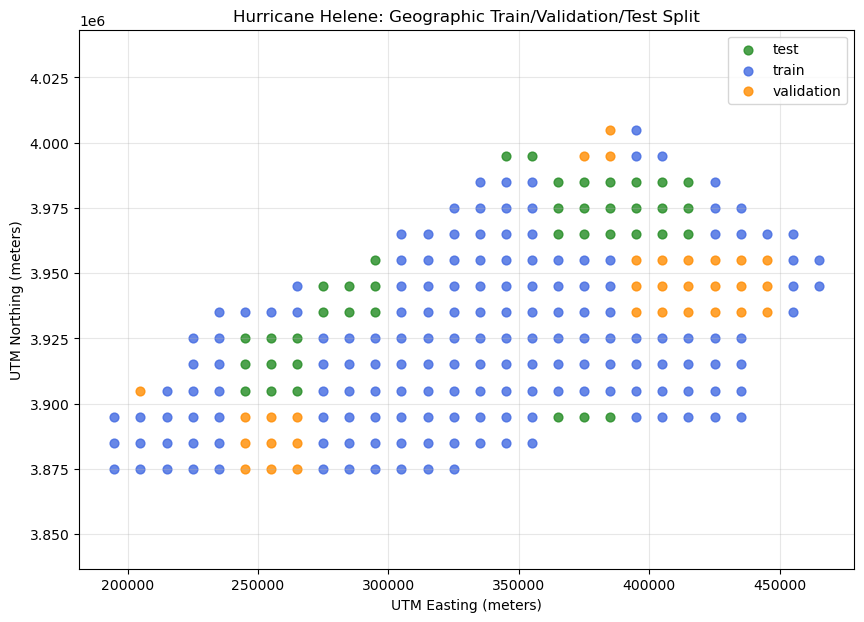

In [273]:
import matplotlib.pyplot as plt

colors = {
    "train": "royalblue",
    "validation": "darkorange",
    "test": "forestgreen"
}

plt.figure(figsize=(10, 7))

for split_name, group in df_split.groupby("split"):
    plt.scatter(
        group["center_x"],
        group["center_y"],
        label=split_name,
        color=colors[split_name],
        s=40,
        alpha=0.8
    )

plt.xlabel("UTM Easting (meters)")
plt.ylabel("UTM Northing (meters)")
plt.title("Hurricane Helene: Geographic Train/Validation/Test Split")
plt.legend()
plt.axis("equal")
plt.grid(alpha=0.3)
plt.show()

In [267]:
df_split = df_split.sort_values("tile_index").reset_index(drop=True)

df_split.to_csv(
    "helene_tile_splits.csv",
    index=False
)

print("Saved helene_tile_splits.csv")

Saved helene_tile_splits.csv


In [272]:
# Keep all 232 tiles in their original geographic splits
df_final = df_split.sort_values("tile_index").copy()

# Verify the assignments
assert len(df_final) == 232
assert df_final["tile_index"].is_unique
assert df_final["spatial_group"].groupby(
    df_final["spatial_group"]
).size().sum() == 232

# Save
df_final.to_csv("helene_tile_splits.csv", index=False)

print("Saved 232 tiles.")
print(df_final["split"].value_counts())

Saved 232 tiles.
split
train         162
test           39
validation     31
Name: count, dtype: int64


In [303]:
train_df.to_csv("train_split.csv", index=False)
val_df.to_csv("val_split.csv", index=False)
test_df.to_csv("test_split.csv", index=False)
print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))

Train: 162
Validation: 31
Test: 39


In [304]:
print("Train columns:", train_df.columns.tolist())
print("Validation columns:", val_df.columns.tolist())
print("Test columns:", test_df.columns.tolist())

display(train_df.head())

Train columns: ['tile_index', 'Tile', 'center_x', 'center_y', 'block_x', 'block_y', 'spatial_group', 'split']
Validation columns: ['tile_index', 'Tile', 'center_x', 'center_y', 'block_x', 'block_y', 'spatial_group', 'split']
Test columns: ['tile_index', 'Tile', 'center_x', 'center_y', 'block_x', 'block_y', 'spatial_group', 'split']


,tile_index,Tile,center_x,center_y,block_x,block_y,spatial_group,split
0,0,tile_000,194960,3875020,6,129,6_129,train
1,1,tile_001,194960,3885020,6,129,6_129,train
2,2,tile_002,194960,3895020,6,129,6_129,train
3,3,tile_003,204960,3875020,6,129,6_129,train
4,4,tile_004,204960,3885020,6,129,6_129,train


In [305]:
folder = "projects/geospatialfinalproject/assets/Hurricane_Helene_BA"

saved_tiles = ee.FeatureCollection(
    f"{folder}/helene_valid_tiles"
)

print("Saved tiles:", saved_tiles.size().getInfo())

print(
    "First tile IDs:",
    saved_tiles.aggregate_array("tile_id").sort().slice(0, 10).getInfo()
)

print(
    "DataFrame tile indices:",
    train_df["tile_index"].head(10).tolist()
)

Saved tiles: 232
First tile IDs: [0, 1, 2, 14, 15, 16, 17, 28, 29, 30]
DataFrame tile indices: [0, 1, 2, 3, 4, 5, 7, 8, 9, 10]


In [306]:
import pandas as pd

# Get original tile IDs and their center coordinates
saved_tiles = ee.FeatureCollection(
    "projects/geospatialfinalproject/assets/"
    "Hurricane_Helene_BA/helene_valid_tiles"
)

def add_center(feature):
    center = feature.geometry().centroid(
        maxError=1,
        proj=ee.Projection("EPSG:32617")
    )
    coords = center.coordinates()

    return feature.set({
        "center_x": coords.get(0),
        "center_y": coords.get(1)
    })

tiles_with_centers = saved_tiles.map(add_center)

tile_data = tiles_with_centers.select(
    ["tile_id", "center_x", "center_y"]
).getInfo()["features"]

tile_mapping = pd.DataFrame([
    feature["properties"]
    for feature in tile_data
])

print(tile_mapping.head())

        center_x      center_y  tile_id
0  194960.118521  3.875020e+06        0
1  194960.118433  3.885020e+06        1
2  194960.119601  3.895020e+06        2
3  204960.041441  3.875020e+06       14
4  204960.039487  3.885020e+06       15


In [310]:
import pandas as pd

# Combine your existing train/validation/test splits
all_splits = pd.concat(
    [train_df, val_df, test_df],
    ignore_index=True
)

# Keep original data unchanged
splits_fixed = all_splits.copy()
mapping_fixed = tile_mapping.copy()

# Create matching coordinates rounded to the nearest meter
for df in [splits_fixed, mapping_fixed]:
    df["match_x"] = df["center_x"].round().astype(int)
    df["match_y"] = df["center_y"].round().astype(int)

# Match each CSV tile with its Earth Engine tile ID
matched_splits = splits_fixed.merge(
    mapping_fixed[["tile_id", "match_x", "match_y"]],
    on=["match_x", "match_y"],
    how="left",
    validate="one_to_one"
)

print("Matched tiles:", matched_splits["tile_id"].notna().sum())
print("Unmatched tiles:", matched_splits["tile_id"].isna().sum())

display(
    matched_splits[
        ["tile_index", "tile_id", "Tile", "split"]
    ].head(10)
)

Matched tiles: 232
Unmatched tiles: 0


,tile_index,tile_id,Tile,split
0,0,0,tile_000,train
1,1,1,tile_001,train
2,2,2,tile_002,train
3,3,14,tile_003,train
4,4,15,tile_004,train
5,5,16,tile_005,train
6,7,28,tile_007,train
7,8,29,tile_008,train
8,9,30,tile_009,train
9,10,31,tile_010,train


In [311]:
print("Total tiles:", len(matched_splits))
print("Matched:", matched_splits["tile_id"].notna().sum())
print("Unmatched:", matched_splits["tile_id"].isna().sum())

display(
    matched_splits[
        ["tile_index", "tile_id", "Tile", "split"]
    ].head(10)
)

Total tiles: 232
Matched: 232
Unmatched: 0


,tile_index,tile_id,Tile,split
0,0,0,tile_000,train
1,1,1,tile_001,train
2,2,2,tile_002,train
3,3,14,tile_003,train
4,4,15,tile_004,train
5,5,16,tile_005,train
6,7,28,tile_007,train
7,8,29,tile_008,train
8,9,30,tile_009,train
9,10,31,tile_010,train


In [312]:
assert matched_splits["tile_id"].notna().all()
assert matched_splits["tile_id"].is_unique

matched_splits["tile_id"] = matched_splits["tile_id"].astype(int)

matched_splits.drop(
    columns=["match_x", "match_y"],
    errors="ignore"
).to_csv(
    "helene_spatial_splits_mapped.csv",
    index=False
)

print("Successfully saved 232 matched tiles!")

Successfully saved 232 matched tiles!


In [287]:
import ctypes

try:
    ctypes.WinDLL(
        r"C:\Users\jazmi\anaconda3\Lib\site-packages\tensorflow\python\_pywrap_tensorflow_internal.pyd"
    )
    print("Native extension loaded successfully")
except OSError as e:
    print("DLL loading error:", e)
    print("Windows error code:", getattr(e, "winerror", None))

DLL loading error: [WinError 1114] A dynamic link library (DLL) initialization routine failed
Windows error code: 1114


In [283]:
df_split.to_csv("helene_spatial_splits.csv", index=False)